# Task 1 - Exploração e preparação dos dados

O notebook está organizado em cinco partes, numeradas de forma contínua dentro de cada parte:

- **Parte A.** Auditoria e qualidade dos dados
- **Parte B.** Análise exploratória (EDA)
- **Parte C.** Análise temporal e drift
- **Parte D.** Leakage e preparação para modelação (inclui o split temporal e o pipeline de pré-processamento)
- **Parte E.** Síntese final

Os valores em falta das variáveis históricas só são substituídos por `-1` no pipeline da Parte D, para que as Partes A a C reflitam os dados reais.

### Glossário rápido

- **Sessão:** um carregamento de um veículo elétrico num posto, do início ao fim.
- **Sessão anormal:** sessão que terminou por uma falha (e não porque acabou normalmente ou porque o utilizador parou). É o que queremos prever.
- **Abnormal rate (taxa de anomalia):** percentagem de sessões anormais. Por exemplo, 18% significa que quase 1 em cada 5 sessões falha.
- **Posto (charging post):** o equipamento onde se carrega o veículo.
- **Histórico:** o que já aconteceu antes da sessão (por exemplo, quantas falhas o posto teve na última semana).
- **Leakage:** usar, sem querer, informação que só se conhece depois da sessão para a prever. O resultado parece ótimo, mas não funciona na vida real.
- **Drift:** quando o comportamento dos dados muda com o tempo.

In [50]:
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# Parte A. Auditoria e qualidade dos dados

## A.1. Carregamento e visualização inicial

O dataset `Charging_Data_educational.csv` é carregado para um `DataFrame` do pandas.

De seguida, são apresentadas as primeiras e as últimas 10 observações do dataset para permitir uma primeira análise da sua estrutura e dos valores existentes.

In [51]:
# Ler o CSV
df = pd.read_csv("Charging_Data_educational.csv")

print("Head Dataset")
display(df.head(10))

print("Tail Dataset")
display(df.tail(10))

Head Dataset


,UserID,Charging Post ID,Location Information,District Name,Order creation time,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,...,user_previous_abnormal_180D,user_previous_abnormal_rate_180D,user_previous_sessions_730D,user_previous_abnormal_730D,user_previous_abnormal_rate_730D,user_days_since_previous_completed_session,user_no_previous_completed_session,user_days_since_previous_completed_abnormal,user_no_previous_completed_abnormal,user_active_sessions_at_start
0,11182,24,Shopping Mall,Tongxiang,2019-12-31 21:26:58\t,37.65,33.62,26.62,60.24,60.24,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
1,27510,67,Government Agency,Xiuzhou,2019-12-31 21:50:58\t,12.03,10.74,8.51,19.25,19.25,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
2,10877,45,Park B,Tongxiang,2019-12-31 22:19:34\t,44.04,39.33,31.14,70.47,70.47,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
3,11591,26,Shopping Mall,Tongxiang,2019-12-31 22:37:24\t,59.51,53.13,42.08,95.21,95.21,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
4,11425,53,Bus Station,Tongxiang,2019-12-31 23:32:28\t,26.19,23.39,18.52,41.91,41.91,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
5,15611,59,Bus Station,Tongxiang,2019-12-31 23:09:57\t,37.35,33.35,26.41,59.76,59.76,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
6,11732,48,Park B,Tongxiang,2019-12-31 23:17:45\t,15.60,13.93,11.03,24.96,24.96,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
7,30016,71,Expressway Service District B,Xiuzhou,2019-12-31 23:12:23\t,21.87,19.53,15.46,34.99,34.99,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
8,5848,27,Shopping Mall,Tongxiang,2019-12-31 23:17:42\t,33.10,29.55,23.41,52.96,52.96,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
9,821,58,Bus Station,Tongxiang,2019-12-31 23:31:31\t,43.44,38.79,30.72,69.51,69.51,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0


Tail Dataset


,UserID,Charging Post ID,Location Information,District Name,Order creation time,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,...,user_previous_abnormal_180D,user_previous_abnormal_rate_180D,user_previous_sessions_730D,user_previous_abnormal_730D,user_previous_abnormal_rate_730D,user_days_since_previous_completed_session,user_no_previous_completed_session,user_days_since_previous_completed_abnormal,user_no_previous_completed_abnormal,user_active_sessions_at_start
441067,11764,27,Shopping Mall,Tongxiang,2021-12-31 23:12:02\t,2.49,0.77,2.34,3.11,3.11,...,1,0.285714,2,1,0.285714,0.387153,0,0.439780,0,0
441068,43803,79,Expressway Service District C,Xiuzhou,2021-12-31 23:14:55\t,5.48,1.78,6.99,8.77,8.77,...,0,0.166667,1,0,0.166667,0.000741,0,NaN,1,0
441069,24971,56,Bus Station,Tongxiang,2021-12-31 23:18:37\t,5.61,1.73,5.00,6.73,6.73,...,0,0.200000,0,0,0.200000,NaN,1,NaN,1,0
441070,11764,27,Shopping Mall,Tongxiang,2021-12-31 23:18:07\t,13.46,4.16,12.67,16.83,16.83,...,1,0.250000,3,1,0.250000,0.000660,0,0.444005,0,0
441071,1974,2,Tourist Attraction,Nanhu,2021-12-31 23:36:00\t,6.36,2.07,0.64,2.71,2.71,...,0,0.200000,0,0,0.200000,NaN,1,NaN,1,0
441072,20170,39,Industrial Park\t,Tongxiang,2021-12-31 23:40:47\t,4.87,1.50,4.83,6.33,6.33,...,0,0.142857,2,0,0.142857,102.044259,0,NaN,1,0
441073,24973,90,Wholesale Market,Xiuzhou,2021-12-31 23:40:24\t,0.41,0.13,0.23,0.36,0.36,...,0,0.125000,3,0,0.125000,0.080451,0,NaN,1,0
441074,11959,60,Bus Station,Tongxiang,2021-12-31 23:46:55\t,7.92,2.44,7.06,9.50,9.50,...,0,0.166667,1,0,0.166667,6.413044,0,NaN,1,0
441075,1974,2,Tourist Attraction,Nanhu,2021-12-31 23:48:11\t,0.00,0.00,0.00,0.00,0.00,...,1,0.333333,1,1,0.333333,0.000741,0,0.000741,0,0
441076,20170,44,Industrial Park\t,Tongxiang,2021-12-31 23:54:12\t,0.00,0.00,0.00,0.00,0.00,...,0,0.142857,2,0,0.142857,102.052662,0,NaN,1,1


In [52]:
#3.Get all information about the dataframe, such as the number of rows, number of columns, column names and their types.
print("-- info --")
print(df.info())
print("\n")

-- info --
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 441077 entries, 0 to 441076
Data columns (total 47 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   UserID                                        441077 non-null  int64  
 1   Charging Post ID                              441077 non-null  int64  
 2   Location Information                          441077 non-null  object 
 3   District Name                                 441077 non-null  object 
 4   Order creation time                           441077 non-null  object 
 5   Transaction power/kwh                         441077 non-null  float64
 6   Electricity cost/Yuan                         441077 non-null  float64
 7   Service charge/Yuan                           441077 non-null  float64
 8   Transaction Amount/Yuan                       441077 non-null  float64
 9   Actual Payment/Yuan                  

In [53]:
#4. View only the variable names in this dataframe.
print("-- variable names --")
print(df.columns)
print("\n")

-- variable names --
Index(['UserID', 'Charging Post ID', 'Location Information', 'District Name',
       'Order creation time', 'Transaction power/kwh', 'Electricity cost/Yuan',
       'Service charge/Yuan', 'Transaction Amount/Yuan', 'Actual Payment/Yuan',
       'Start Time', 'End Time', 'Payment time', 'Temperature(℃)',
       'Relative Humidity(%)', 'Precipitation(mm)', 'end_cause',
       'electricity_price', 'tariff_period', 'post_previous_sessions_1D',
       'post_previous_abnormal_1D', 'post_previous_abnormal_rate_1D',
       'post_previous_sessions_7D', 'post_previous_abnormal_7D',
       'post_previous_abnormal_rate_7D', 'post_previous_sessions_30D',
       'post_previous_abnormal_30D', 'post_previous_abnormal_rate_30D',
       'post_hours_since_previous_completed_session',
       'post_no_previous_completed_session',
       'post_hours_since_previous_completed_abnormal',
       'post_no_previous_completed_abnormal', 'is_new_user',
       'user_previous_sessions_30D', 'user

In [54]:
#5. What is the size of the data set?

print(f"Shape : {df.shape}")
print(f"Size : {df.size}")
print("\n")

Shape : (441077, 47)
Size : 20730619




In [55]:
#6. Get statistics from the dataframe's numerical columns and frequency tables for categorical variables.
display(df.describe())

,UserID,Charging Post ID,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,Temperature(℃),Relative Humidity(%),Precipitation(mm),...,user_previous_abnormal_180D,user_previous_abnormal_rate_180D,user_previous_sessions_730D,user_previous_abnormal_730D,user_previous_abnormal_rate_730D,user_days_since_previous_completed_session,user_no_previous_completed_session,user_days_since_previous_completed_abnormal,user_no_previous_completed_abnormal,user_active_sessions_at_start
count,441077.000000,441077.000000,441077.000000,441077.000000,441077.000000,441077.000000,441077.000000,441077.000000,441077.000000,441077.000000,...,441077.000000,441077.000000,441077.000000,441077.000000,441077.000000,384430.000000,441077.000000,304798.000000,441077.000000,441077.000000
mean,13262.864430,48.829583,16.436574,12.158460,7.450791,19.609251,18.487883,19.708336,75.030351,3.510698,...,30.895948,0.189512,353.165608,57.414277,0.189927,8.253567,0.128429,25.372314,0.308969,0.095255
std,14286.825468,25.045206,13.253881,10.830214,8.152830,15.958935,15.924672,8.481954,12.656150,10.833238,...,116.182109,0.114190,1570.612335,252.481005,0.113385,32.487383,0.334567,57.064240,0.462069,0.565021
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-3.200000,32.000000,0.000000,...,0.000000,0.004739,0.000000,0.000000,0.004673,0.000012,0.000000,0.000012,0.000000,0.000000
25%,2478.000000,26.000000,5.440000,3.340000,1.070000,6.270000,4.600000,12.700000,67.000000,0.000000,...,0.000000,0.113208,3.000000,0.000000,0.115385,0.002512,0.000000,0.183469,0.000000,0.000000
50%,8819.000000,51.000000,15.150000,10.110000,5.100000,18.440000,16.650000,21.000000,76.000000,0.000000,...,2.000000,0.169818,21.000000,3.000000,0.166667,0.718194,0.000000,4.399132,0.000000,0.000000
75%,19614.000000,69.000000,24.740000,18.160000,10.990000,29.700000,29.370000,26.900000,84.000000,1.200000,...,10.000000,0.218750,89.000000,13.000000,0.219178,2.800868,0.000000,21.798695,1.000000,0.000000
max,56117.000000,92.000000,117.740000,121.160000,101.260000,147.170000,147.170000,33.600000,99.000000,152.100000,...,969.000000,0.942029,14566.000000,2295.000000,0.942029,708.008403,1.000000,702.308067,1.000000,14.000000


In [56]:
#7.Get values from the dataframe's text columns.
display(df.select_dtypes(include="object"))

,Location Information,District Name,Order creation time,Start Time,End Time,Payment time,end_cause,tariff_period
0,Shopping Mall,Tongxiang,2019-12-31 21:26:58\t,2019-12-31 21:27:03,2020-01-01 05:03:53,2020-01-01 05:03:40\t,Charging ends normally,peak_21_22
1,Government Agency,Xiuzhou,2019-12-31 21:50:58\t,2019-12-31 21:50:56,2020-01-01 08:52:56,2020-01-01 08:53:08\t,Charging ends normally,peak_21_22
2,Park B,Tongxiang,2019-12-31 22:19:34\t,2019-12-31 22:12:46,2020-01-01 00:36:26,2020-01-01 00:43:11\t,Charging ends normally,off_peak_22_24
3,Shopping Mall,Tongxiang,2019-12-31 22:37:24\t,2019-12-31 22:38:55,2020-01-01 19:34:51,2020-01-01 19:33:17\t,Charging ends normally,off_peak_22_24
4,Bus Station,Tongxiang,2019-12-31 23:32:28\t,2019-12-31 23:06:44,2020-01-01 07:48:26,2020-01-01 08:14:20\t,Charging ends normally,off_peak_22_24
...,...,...,...,...,...,...,...,...
441072,Industrial Park\t,Tongxiang,2021-12-31 23:40:47\t,2021-12-31 23:40:08,2021-12-31 23:53:25,2021-12-31 23:54:10\t,Charging ends normally,off_peak_22_24
441073,Wholesale Market,Xiuzhou,2021-12-31 23:40:24\t,2021-12-31 23:40:25,2021-12-31 23:45:53,2021-12-31 23:46:02\t,User stops charging,off_peak_22_24
441074,Bus Station,Tongxiang,2021-12-31 23:46:55\t,2021-12-31 23:44:43,2021-12-31 23:58:03,2022-01-01 00:00:22\t,Charging ends normally,off_peak_22_24
441075,Tourist Attraction,Nanhu,2021-12-31 23:48:11\t,2021-12-31 23:48:14,2021-12-31 23:49:27,2022-01-01 00:11:10\t,Vehicle communications failure,off_peak_22_24


## A.2. Valores em falta

Contagem de `NaN` por coluna, remoção das linhas totalmente vazias e análise das colunas com valores em falta.

In [57]:
#8.Check null values from columns dataframe.
print("-- Count number of Nas per column. --")
print(df.isna().sum())
print(f"Initial rows: {len(df)}")
print("\n")

-- Count number of Nas per column. --
UserID                                               0
Charging Post ID                                     0
Location Information                                 0
District Name                                        0
Order creation time                                  0
Transaction power/kwh                                0
Electricity cost/Yuan                                0
Service charge/Yuan                                  0
Transaction Amount/Yuan                              0
Actual Payment/Yuan                                  0
Start Time                                           0
End Time                                             0
Payment time                                         0
Temperature(℃)                                       0
Relative Humidity(%)                                 0
Precipitation(mm)                                    0
end_cause                                            0
electricity_price          

In [58]:
#9. Remove the line with all columns: NaN.
print("-- Remove rows where all columns are NaN --")

df.dropna(how="all", inplace=True)

print(f"Remaining rows: {len(df)}")
print(f"Rows with all NaN: {df.isna().all(axis=1).sum()}")

print("\nMissing values per column:")
print(df.isna().sum())

-- Remove rows where all columns are NaN --
Remaining rows: 441077
Rows with all NaN: 0

Missing values per column:
UserID                                               0
Charging Post ID                                     0
Location Information                                 0
District Name                                        0
Order creation time                                  0
Transaction power/kwh                                0
Electricity cost/Yuan                                0
Service charge/Yuan                                  0
Transaction Amount/Yuan                              0
Actual Payment/Yuan                                  0
Start Time                                           0
End Time                                             0
Payment time                                         0
Temperature(℃)                                       0
Relative Humidity(%)                                 0
Precipitation(mm)                                    0
end_

In [59]:
# 10. Check columns with many null values

print("-- Columns with null values --")

nulls = df.isna().sum()
null_percentage = (df.isna().mean() * 100)

null_summary = pd.DataFrame({
    "Null_Count": nulls,
    "Null_Percentage": null_percentage
})

# Mostrar apenas colunas que têm valores nulos
null_summary = null_summary[null_summary["Null_Count"] > 0]

display(null_summary)


#verificar qual o motivo pelo qual tem valores null e atribuir uma label para cada uma das situações (-1)

-- Columns with null values --


,Null_Count,Null_Percentage
post_hours_since_previous_completed_session,92,0.020858
post_hours_since_previous_completed_abnormal,367,0.083205
user_days_since_previous_completed_session,56647,12.842882
user_days_since_previous_completed_abnormal,136279,30.896873


In [60]:
# Pair each historical time variable with its corresponding indicator
missing_history_pairs = {
    "post_hours_since_previous_completed_session":
        "post_no_previous_completed_session",

    "post_hours_since_previous_completed_abnormal":
        "post_no_previous_completed_abnormal",

    "user_days_since_previous_completed_session":
        "user_no_previous_completed_session",

    "user_days_since_previous_completed_abnormal":
        "user_no_previous_completed_abnormal"
}

for time_col, flag_col in missing_history_pairs.items():

    print(f"\n--- {time_col} ---")

    print(pd.crosstab(
        df[flag_col],
        df[time_col].isna(),
        rownames=[flag_col],
        colnames=["Time is missing"],
        margins=True
    ))


--- post_hours_since_previous_completed_session ---
Time is missing                      False  True     All
post_no_previous_completed_session                      
0                                   440985     0  440985
1                                        0    92      92
All                                 440985    92  441077

--- post_hours_since_previous_completed_abnormal ---
Time is missing                       False  True     All
post_no_previous_completed_abnormal                      
0                                    440710     0  440710
1                                         0   367     367
All                                  440710   367  441077

--- user_days_since_previous_completed_session ---
Time is missing                      False   True     All
user_no_previous_completed_session                       
0                                   384430      0  384430
1                                        0  56647   56647
All                               

### Notas

A análise confirmou que os valores em falta nas quatro variáveis de tempo histórico não resultam de valores desconhecidos nem de erros de qualidade dos dados. Ocorrem porque **não existe uma sessão anterior concluída (ou anormal)** a partir da qual seja possível calcular o tempo decorrido.

Por isso, os `NaN` são mantidos durante a auditoria e a EDA, e as variáveis indicadoras `no_previous` permitem identificá-los. A sua representação numérica (`-1`) é definida no pipeline de pré-processamento (secção D.9), para não distorcer as estatísticas e os gráficos da EDA.

## A.3. Normalização dos nomes das variáveis

Normalizar os nomes das colunas para obter uma nomenclatura consistente.

São aplicadas as seguintes transformações:
- remoção de espaços no início e no fim;
- conversão para letras minúsculas;
- substituição de caracteres especiais por `_`;
- remoção de `_` no início e no fim.

In [61]:
#11.Standardize columns names

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-zA-Z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns)
print("\n")

Index(['userid', 'charging_post_id', 'location_information', 'district_name',
       'order_creation_time', 'transaction_power_kwh', 'electricity_cost_yuan',
       'service_charge_yuan', 'transaction_amount_yuan', 'actual_payment_yuan',
       'start_time', 'end_time', 'payment_time', 'temperature',
       'relative_humidity', 'precipitation_mm', 'end_cause',
       'electricity_price', 'tariff_period', 'post_previous_sessions_1d',
       'post_previous_abnormal_1d', 'post_previous_abnormal_rate_1d',
       'post_previous_sessions_7d', 'post_previous_abnormal_7d',
       'post_previous_abnormal_rate_7d', 'post_previous_sessions_30d',
       'post_previous_abnormal_30d', 'post_previous_abnormal_rate_30d',
       'post_hours_since_previous_completed_session',
       'post_no_previous_completed_session',
       'post_hours_since_previous_completed_abnormal',
       'post_no_previous_completed_abnormal', 'is_new_user',
       'user_previous_sessions_30d', 'user_previous_abnormal_30d',
   

## A.4. Deteção de linhas duplicadas

Verificar o número de linhas duplicadas existentes no DataFrame e removê-las, se existirem.

O dataset não tem linhas duplicadas, pelo que nenhuma linha é removida.

In [62]:
#12.Número de linhas duplicadas
print(f"Número de linhas duplicadas: {df.duplicated().sum()}")

df.drop_duplicates(inplace=True)
print(f"Linhas após remover duplicadas: {len(df)}")

Número de linhas duplicadas: 0
Linhas após remover duplicadas: 441077


## A.5. Validação de valores negativos

As variáveis de energia, monetárias, precipitação e preço não devem assumir valores negativos.

In [63]:
# Variáveis que não devem assumir valores negativos
non_negative_columns = [
    "transaction_power_kwh",
    "electricity_cost_yuan",
    "service_charge_yuan",
    "transaction_amount_yuan",
    "actual_payment_yuan",
    "precipitation_mm",
    "electricity_price"
]

for col in non_negative_columns:
    negative_count = (df[col] < 0).sum()
    
    print(f"{col}: {negative_count} valores negativos")

transaction_power_kwh: 0 valores negativos
electricity_cost_yuan: 0 valores negativos
service_charge_yuan: 0 valores negativos
transaction_amount_yuan: 0 valores negativos
actual_payment_yuan: 0 valores negativos
precipitation_mm: 0 valores negativos
electricity_price: 0 valores negativos


## A.6. Validação da temperatura

Analisar os valores mínimo e máximo da temperatura e verificar se existem valores fora de um intervalo considerado plausível:

- abaixo de `-30 ºC`;
- acima de `50 ºC`.

In [64]:
print("Temperatura mínima:", df["temperature"].min())
print("Temperatura máxima:", df["temperature"].max())

print("\nValores abaixo de -30 ºC:")
print((df["temperature"] < -30).sum())

print("\nValores acima de 50 ºC:")
print((df["temperature"] > 50).sum())

Temperatura mínima: -3.2
Temperatura máxima: 33.6

Valores abaixo de -30 ºC:
0

Valores acima de 50 ºC:
0


## A.7. Validação da humidade relativa

Verificar se existem valores de humidade relativa fora do intervalo válido de **0% a 100%**.

In [65]:
print("Humidade mínima:", df["relative_humidity"].min())
print("Humidade máxima:", df["relative_humidity"].max())

invalid_humidity = (
    (df["relative_humidity"] < 0) |
    (df["relative_humidity"] > 100)
)

print("\nValores de humidade fora do intervalo [0, 100]:")
print(invalid_humidity.sum())

Humidade mínima: 32
Humidade máxima: 99

Valores de humidade fora do intervalo [0, 100]:
0


## A.8. Validação da precipitação

Analisar os valores mínimo e máximo da precipitação e verificar se existem valores negativos.

A precipitação não deve assumir valores inferiores a zero.

In [66]:
print("Precipitação mínima:", df["precipitation_mm"].min())
print("Precipitação máxima:", df["precipitation_mm"].max())

print("\nValores negativos:")
print((df["precipitation_mm"] < 0).sum())

Precipitação mínima: 0.0
Precipitação máxima: 152.1

Valores negativos:
0


## A.9. Conversão das variáveis temporais

Converter as variáveis relacionadas com datas e horas para o tipo `datetime` do pandas:

- `order_creation_time`;
- `start_time`;
- `end_time`;
- `payment_time`.

Valores que não possam ser convertidos são transformados em `NaT`.

In [67]:
datetime_columns = [
    "order_creation_time",
    "start_time",
    "end_time",
    "payment_time"
]

for col in datetime_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print(df[datetime_columns].dtypes)

order_creation_time    datetime64[ns]
start_time             datetime64[ns]
end_time               datetime64[ns]
payment_time           datetime64[ns]
dtype: object


## A.10. Validação da ordem temporal

Verificar possíveis inconsistências na ordem temporal dos eventos.

São analisadas as seguintes relações:
- `end_time < start_time`;
- `payment_time < start_time`;
- `start_time < order_creation_time`.

O objetivo é identificar situações que possam indicar problemas nos dados.

In [68]:
# End time cannot occur before start time
invalid_end = df["end_time"] < df["start_time"]

print("End Time < Start Time:", invalid_end.sum())

invalid_payment = df["payment_time"] < df["start_time"]

print("Payment Time < Start Time:", invalid_payment.sum())

invalid_start = df["start_time"] < df["order_creation_time"]

print("Start Time < Order Creation Time:", invalid_start.sum())

End Time < Start Time: 0
Payment Time < Start Time: 1554
Start Time < Order Creation Time: 248588


Foram identificadas 1.554 observações em que o pagamento foi registado antes do início da sessão e 248.588 observações em que o início da sessão antecede o Order creation time. No entanto, estas relações não foram consideradas inconsistências automaticamente, uma vez que o enunciado não estabelece uma ordem temporal obrigatória entre estes eventos. Assim, não foram realizadas alterações com base nestas verificações.

## A.11. Análise das variáveis categóricas

Identificar as variáveis categóricas (`object`) e apresentar a frequência de cada valor, incluindo os valores em falta.

Esta análise permite conhecer as categorias existentes e a sua distribuição.

In [69]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- location_information ---
location_information
Bus Station                      60809
Park B                           57294
Shopping Mall                    56605
Expressway Service District C    50187
Government Agency                36551
Wholesale Market                 34491
Technology Park                  28867
Park A                           27845
Tourist Attraction               23659
Financial Industrial Park        18923
Industrial Park\t                18370
Expressway Service District A    15075
Expressway Service District B    12401
Name: count, dtype: int64

--- district_name ---
district_name
Tongxiang    220923
Xiuzhou      148705
Nanhu         71449
Name: count, dtype: int64

--- end_cause ---
end_cause
Charging ends normally                                          203201
User stops charging                                             155942
Other faults of the charging pile                                20114
DC Output Fault                                    

## A.12. Relação entre período tarifário e preço da eletricidade

Utilizar uma tabela de contingência para analisar a relação entre `tariff_period` e `electricity_price`.

A tabela apresenta a frequência das combinações entre o período tarifário e o preço da eletricidade.

In [70]:
print(
    pd.crosstab(
        df["tariff_period"],
        df["electricity_price"]
    )
)

electricity_price  0.3784  0.9014  1.2064
tariff_period                            
off_peak_00_08      48633       0       0
off_peak_11_13      61760       0       0
off_peak_22_24      43704       0       0
peak_08_11              0   48977       0
peak_13_19              0  167118       0
peak_21_22              0   22843       0
sharp_19_21             0       0   48042


## A.13. Estatísticas do preço por período tarifário

Agrupar os dados por `tariff_period` e calcular, para `electricity_price`:
- valor mínimo;
- valor máximo;
- número de preços distintos (`nunique`).

Esta análise permite comparar os preços praticados nos diferentes períodos tarifários.

In [71]:
print(
    df.groupby("tariff_period")["electricity_price"]
      .agg(["min", "max", "nunique"])
)

                   min     max  nunique
tariff_period                          
off_peak_00_08  0.3784  0.3784        1
off_peak_11_13  0.3784  0.3784        1
off_peak_22_24  0.3784  0.3784        1
peak_08_11      0.9014  0.9014        1
peak_13_19      0.9014  0.9014        1
peak_21_22      0.9014  0.9014        1
sharp_19_21     1.2064  1.2064        1


## A.14. Resumo da auditoria

Nesta etapa foi feita a exploração inicial e a validação do dataset:
- os `NaN` das variáveis de tempo histórico correspondem a ausência de histórico anterior (substituídos por `-1` apenas no pipeline, secção D.9);
- os nomes das colunas foram normalizados e as variáveis temporais convertidas para `datetime`;
- não existem linhas duplicadas nem valores fora dos intervalos plausíveis (negativos, temperatura, humidade, precipitação);
- as ordens temporais atípicas e os outliers foram identificados, mas mantidos.

Além das linhas totalmente vazias, nenhuma linha foi removida. O dataset fica caracterizado e pronto para a EDA.

# Parte B. Análise exploratória (EDA)

## B.1. Distribuição do target e desequilíbrio de classes

Vamos medir o número e a percentagem de sessõees normais e anormais. A variáível `end_cause` não será utilizada como predictor.

**Em termos simples.** Contámos quantas sessões correm bem e quantas falham. Cerca de 1 em cada 5 falha.

**O que significa para o negócio.** Uma sessão que falha é um cliente frustrado, receita perdida e, muitas vezes, uma visita de manutenção. Com 1 falha em cada 5 sessões, o problema é grande o suficiente para justificar um sistema que avise antes. Atenção: como 4 em cada 5 sessões correm bem, um sistema que dissesse sempre «vai correr bem» acertaria cerca de 81% das vezes e não serviria para nada. Por isso o modelo não é avaliado só pela percentagem de acertos.

,sessions,percentage
is_abnormal,,
0,359143,81.424105
1,81934,18.575895


Razao maioritaria/minoritaria: 4.38


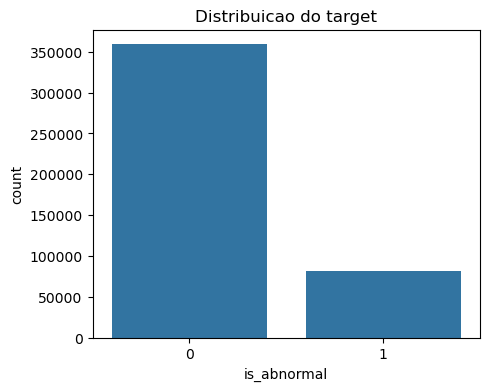

In [72]:
if "is_abnormal" not in df.columns:
    if "end_cause" not in df.columns:
        raise KeyError("Nao existe is_abnormal nem end_cause para definir o target.")
    NORMAL_END_CAUSES = {
        "Charging ends normally",
        "User stops charging",
    }
    df["is_abnormal"] = (~df["end_cause"].isin(NORMAL_END_CAUSES)).astype(int)

target_summary = df["is_abnormal"].value_counts().sort_index().rename_axis("is_abnormal").to_frame("sessions")
target_summary["percentage"] = target_summary["sessions"] / len(df) * 100
display(target_summary)
print(f"Razao maioritaria/minoritaria: {target_summary['sessions'].max() / target_summary['sessions'].min():.2f}")
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="is_abnormal")
plt.title("Distribuicao do target")
save_fig("target_distribution")
plt.show()

### Composição do target por `end_cause`
Distribuição de todas as causas de término, indicando quais são consideradas normais e quais anormais. A escala é logarítmica porque as causas raras seriam invisíveis.

**Em termos simples.** O gráfico mostra os vários motivos pelos quais uma sessão termina e quantas sessões há de cada tipo (a escala é especial, para que os motivos raros também se vejam).

**O que significa para o negócio.** Os motivos de falha mais frequentes são os primeiros a investigar, porque resolvê-los melhora mais sessões. Os motivos raros afetam poucos clientes, mas podem indicar avarias graves. Quando o utilizador pára o carregamento por vontade própria («User stops charging») não é uma falha da rede, por isso conta como normal.

,sessions,percentage,tipo
end_cause,,,
Charging ends normally,203201,46.069280,normal
User stops charging,155942,35.354825,normal
Other faults of the charging pile,20114,4.560202,abnormal
DC Output Fault,14813,3.358371,abnormal
Vehicle communications failure,13936,3.159539,abnormal
Faulty charging connection,8539,1.935943,abnormal
BMS failure,8170,1.852284,abnormal
Failure of non-system control loop components and assemblies,6941,1.573648,abnormal
Vehicle charging faults,6429,1.457569,abnormal


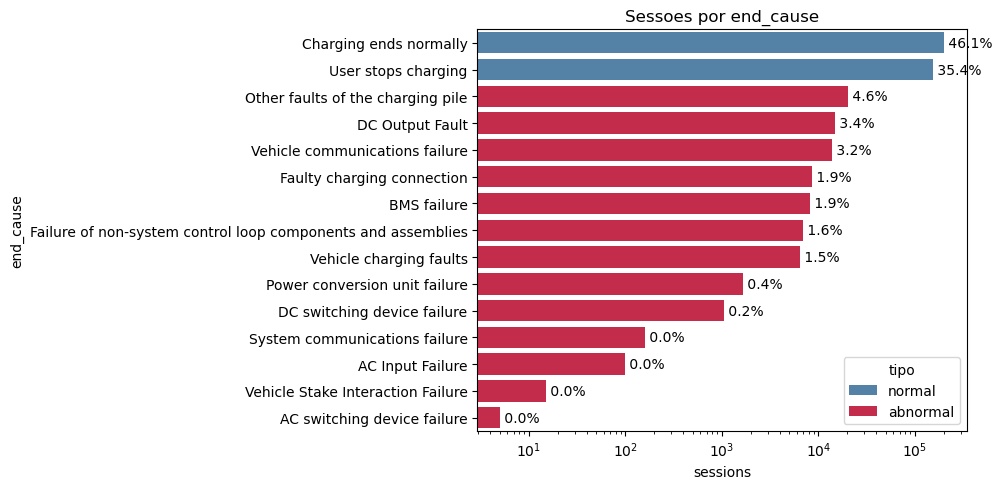

In [73]:
normal_causes = {"Charging ends normally", "User stops charging"}
cause_df = df["end_cause"].value_counts().rename("sessions").to_frame()
cause_df.index.name = "end_cause"
cause_df["percentage"] = cause_df["sessions"] / len(df) * 100
cause_df["tipo"] = np.where(cause_df.index.isin(normal_causes), "normal", "abnormal")
display(cause_df)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=cause_df.reset_index(), y="end_cause", x="sessions", hue="tipo",
            palette={"normal": "steelblue", "abnormal": "crimson"}, dodge=False, ax=ax)
ax.set_xscale("log")
for pos, pct in enumerate(cause_df["percentage"]):
    ax.text(cause_df["sessions"].iloc[pos], pos, f" {pct:.1f}%", va="center")
ax.set_title("Sessoes por end_cause")
plt.tight_layout()
save_fig("end_cause_distribution")
plt.show()

## B.2. Variáveis numéricas e relação com o target

Aqui comparamos as distribuições e os valores por classe, excluindo `userid` e `charging_post_id`, que são identificadores. Os outliers são observados, mas não são removidos.

is_abnormal                                    0          1
post_previous_sessions_1d      median  10.000000  11.000000
                               mean    10.595387  12.773781
post_previous_abnormal_1d      median   1.000000   3.000000
                               mean     1.515229   6.132509
post_previous_abnormal_rate_1d median   0.125000   0.263158
...                                          ...        ...
relative_humidity              mean    75.028267  75.039483
precipitation_mm               median   0.000000   0.000000
                               mean     3.484655   3.624853
electricity_price              median   0.901400   0.901400
                               mean     0.753873   0.743266

[64 rows x 2 columns]

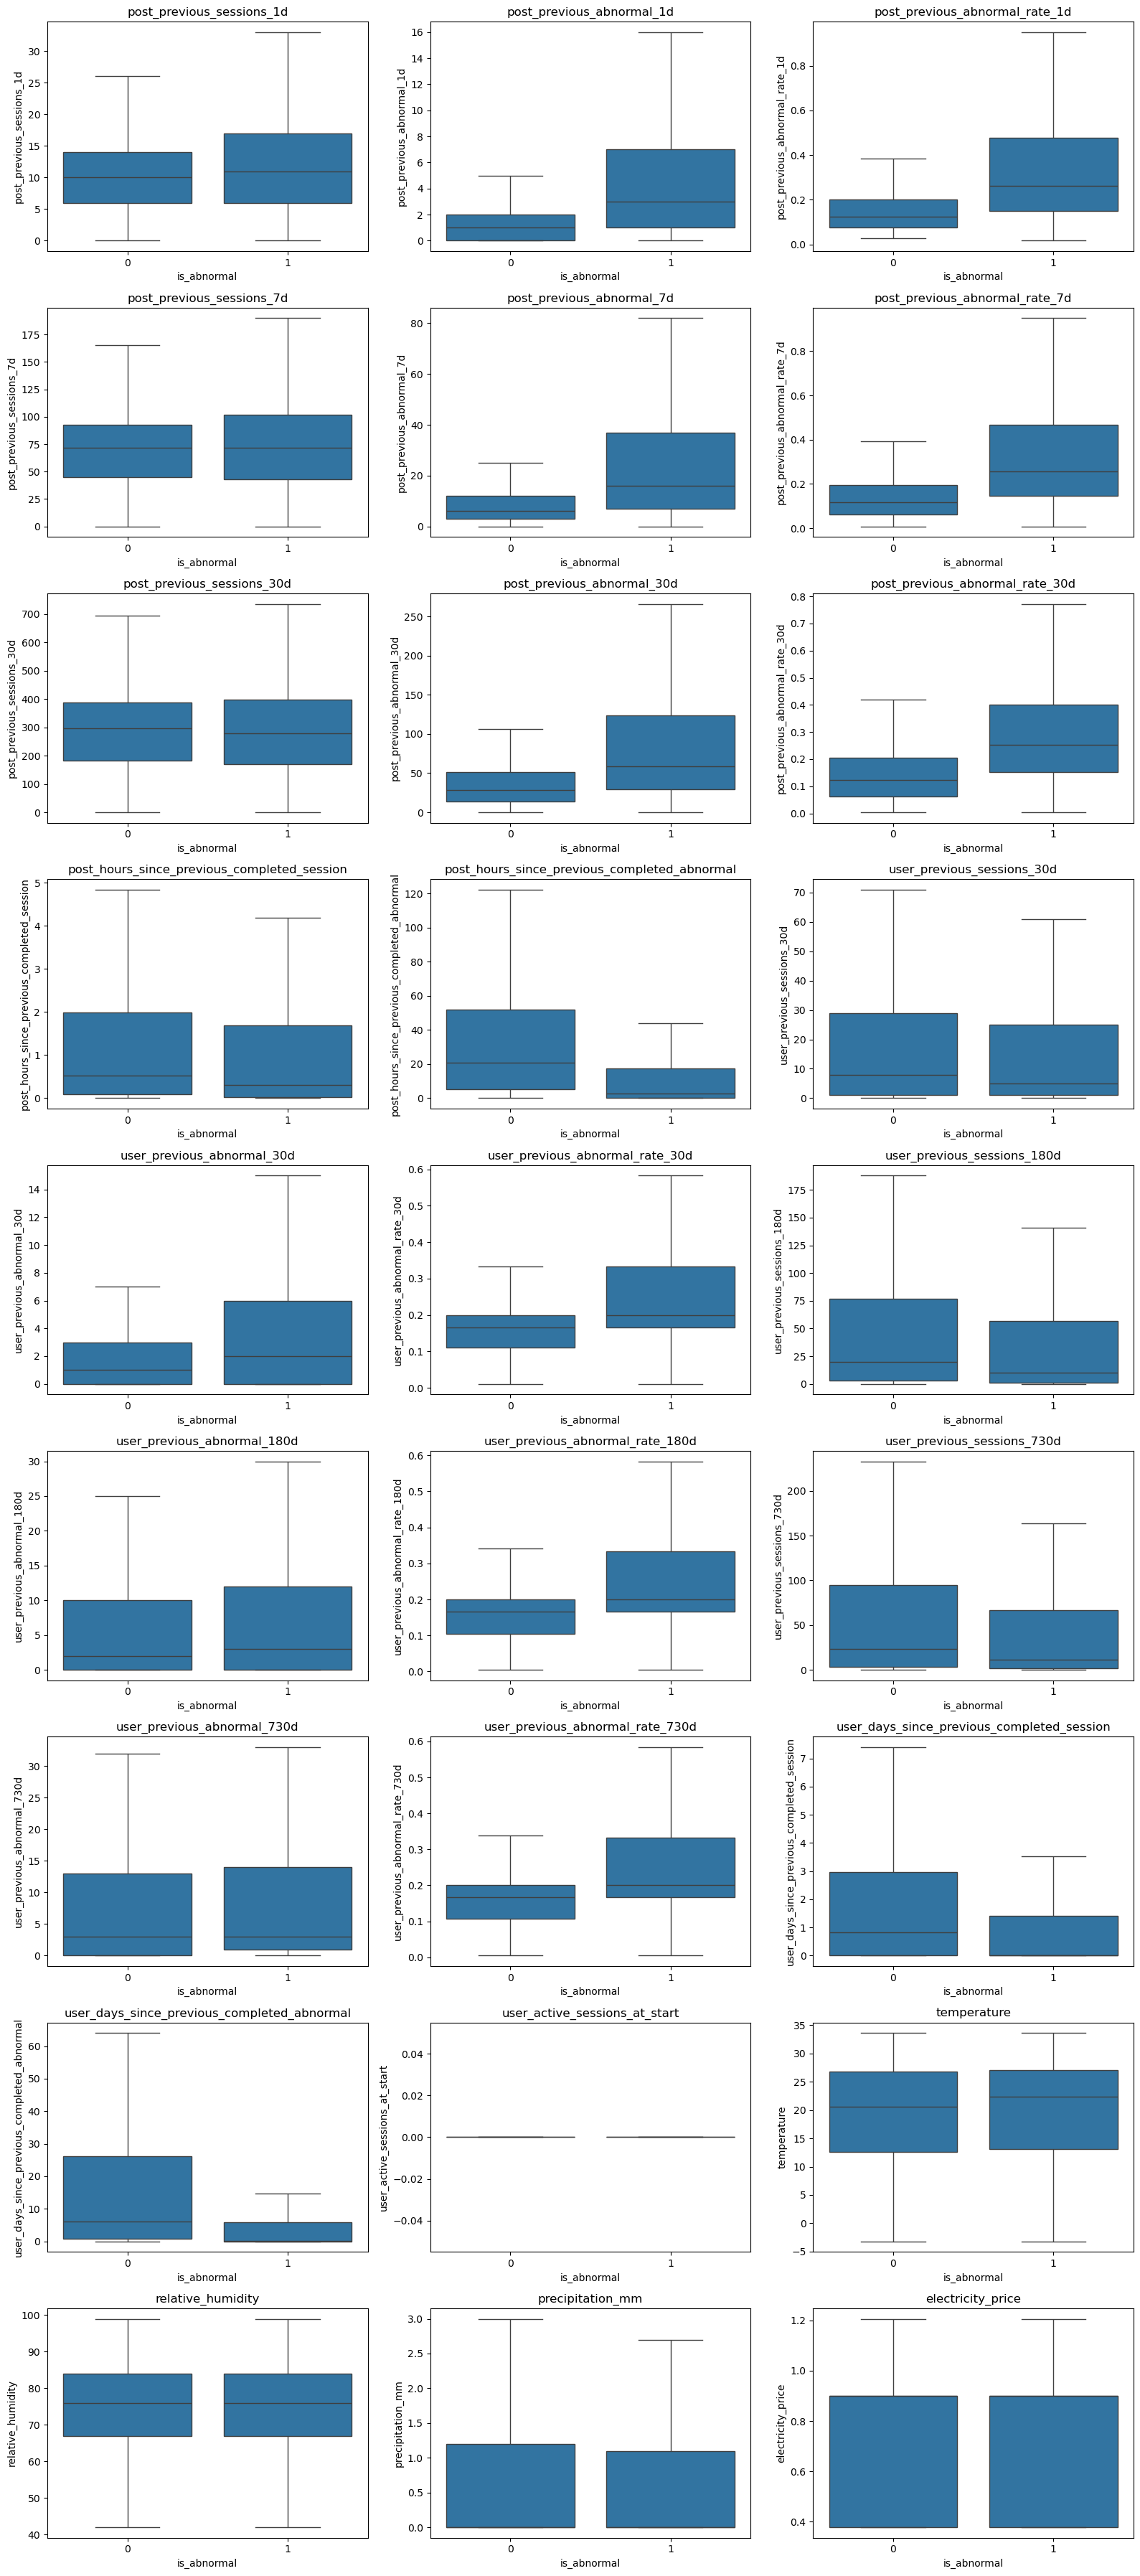

In [74]:
history_cols = [c for c in df.columns if c.startswith("post_") or c.startswith("user_")] + ["is_new_user"]
environment_cols = [c for c in ["temperature", "relative_humidity", "precipitation_mm", "electricity_price"] if c in df.columns]
eda_numeric = [c for c in history_cols + environment_cols if c in df.columns]
display(df.groupby("is_abnormal")[eda_numeric].agg(["median", "mean"]).T)

plot_cols = [c for c in eda_numeric if df[c].nunique(dropna=True) > 2]
fig, axes = plt.subplots(int(np.ceil(len(plot_cols) / 3)), 3, figsize=(16, 4 * int(np.ceil(len(plot_cols) / 3))))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, plot_cols):
    sns.boxplot(data=df, x="is_abnormal", y=col, showfliers=False, ax=ax)
    ax.set_title(col)
for ax in axes[len(plot_cols):]:
    ax.remove()
plt.tight_layout()
save_fig("numeric_by_class_boxplot")
plt.show()

Diferenças nas medianas, médias ou dispersões indicam variáveis com comportamentos diferentes entre as classes e que poderão ser relevantes. As distribuições assimétricas devem ser consideradas mais tarde. Estas diferenças representam associações e não demonstram causalidade.

**Como ler os gráficos de caixa.** Cada caixa mostra onde estão as sessões «típicas»: a linha do meio é o valor central e a caixa contém metade das sessões. Há uma caixa para as sessões normais e outra para as anormais. Se as duas caixas estão em sítios diferentes, essa informação ajuda a distinguir uma sessão que vai falhar de uma que não vai.

**O que significa para o negócio.** Muitas destas variáveis são o «registo recente» do posto e do cliente, por exemplo quantas falhas houve ultimamente. Se as sessões que falham vêm de postos ou clientes com mais falhas recentes, os problemas tendem a repetir-se. Isso é uma boa notícia: significa que é possível antecipar falhas e dirigir a manutenção aos postos de risco. As variáveis cujas caixas são iguais nas duas classes pouco ajudam.

### Distribuições por classe
Histogramas normalizados por classe (`common_norm=False`), cortados entre os percentis 1 e 99 para não serem dominados por extremos. Os valores sem histórico (`NaN`) ficam de fora.

**Como ler.** Cada curva mostra que valores são mais comuns nas sessões normais e nas sessões anormais. Se as duas curvas são quase iguais, a variável não ajuda a distinguir os dois casos; se são diferentes, ajuda.

**O que significa para o negócio.** Mostra que informação, conhecida antes de o carregamento começar, pode servir de sinal de alerta.

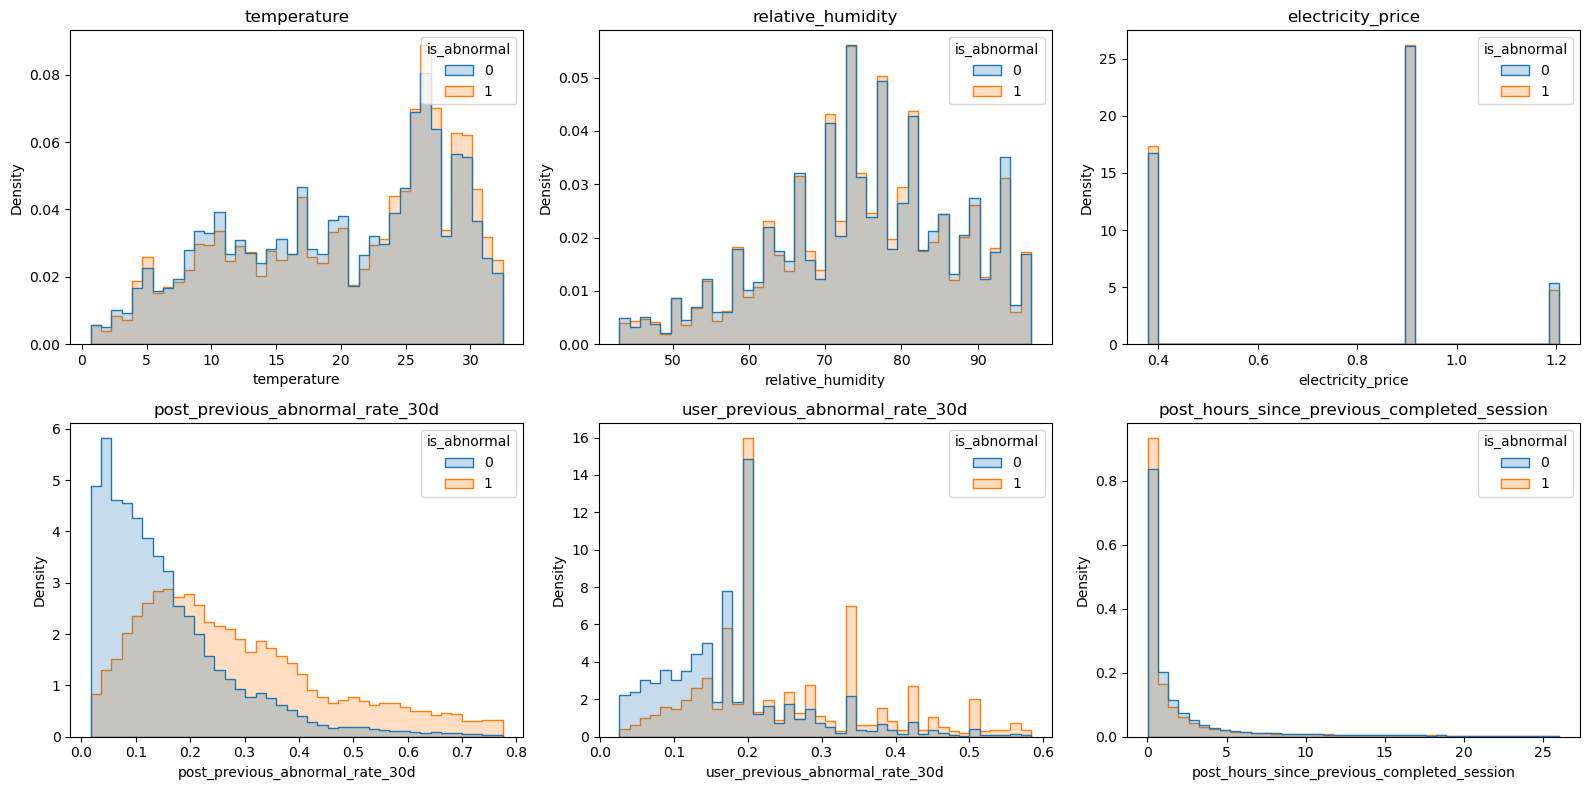

In [75]:
dist_cols = [c for c in ["temperature", "relative_humidity", "electricity_price",
                         "post_previous_abnormal_rate_30d", "user_previous_abnormal_rate_30d",
                         "post_hours_since_previous_completed_session"] if c in df.columns]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), dist_cols):
    lo, hi = df[col].quantile([0.01, 0.99])
    sns.histplot(data=df, x=col, hue="is_abnormal", stat="density", common_norm=False,
                 element="step", bins=40, binrange=(lo, hi), ax=ax)
    ax.set_title(col)
plt.tight_layout()
save_fig("numeric_by_class_hist")
plt.show()

### Distribuições por classe
Histogramas normalizados por classe (`common_norm=False`), cortados entre os percentis 1 e 99 para não serem dominados por extremos. Os valores sem histórico (`NaN`) ficam de fora.

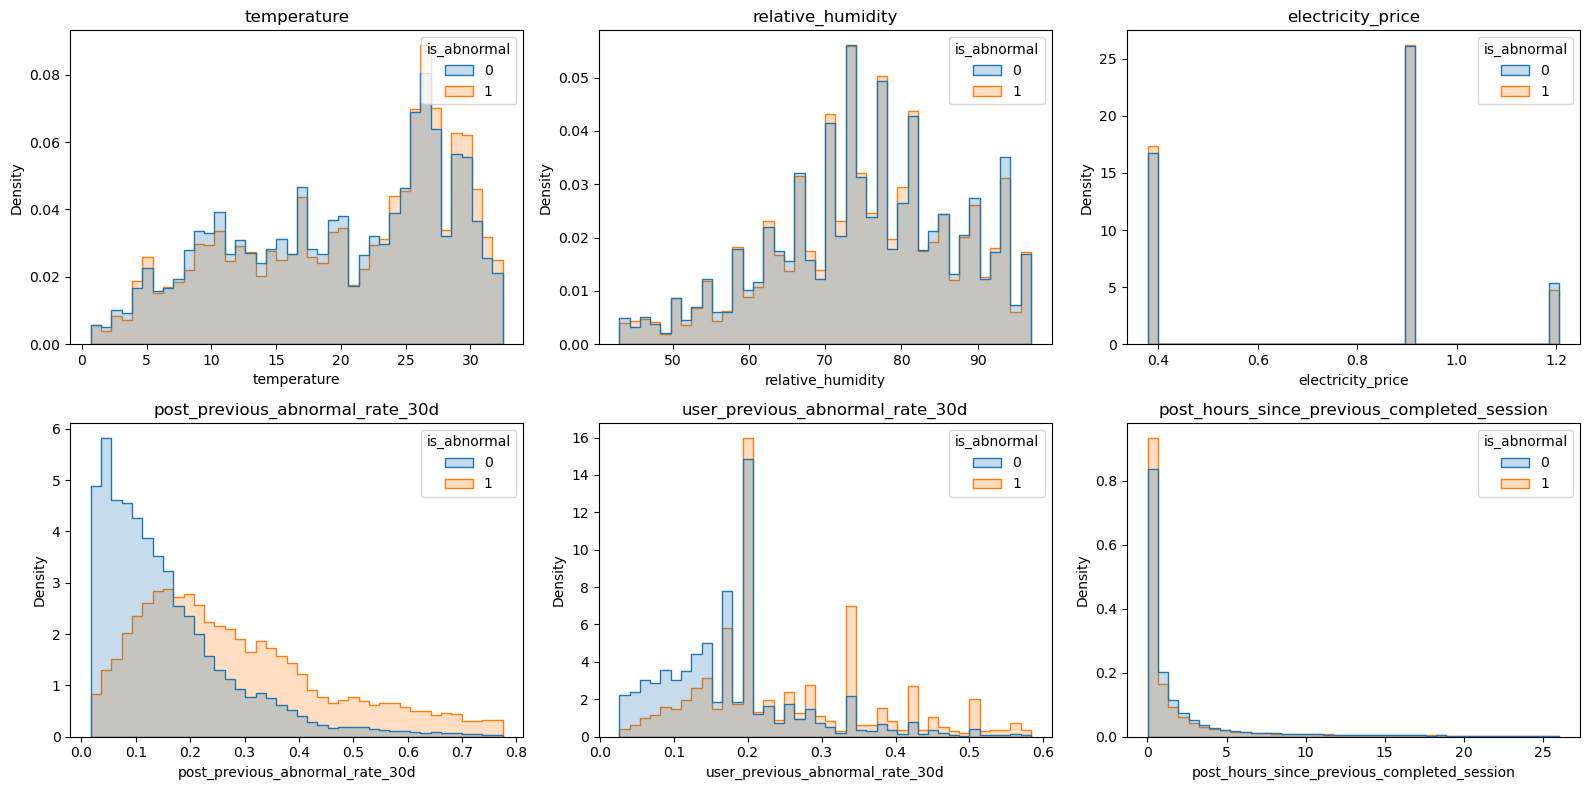

In [76]:
dist_cols = [c for c in ["temperature", "relative_humidity", "electricity_price",
                         "post_previous_abnormal_rate_30d", "user_previous_abnormal_rate_30d",
                         "post_hours_since_previous_completed_session"] if c in df.columns]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), dist_cols):
    lo, hi = df[col].quantile([0.01, 0.99])
    sns.histplot(data=df, x=col, hue="is_abnormal", stat="density", common_norm=False,
                 element="step", bins=40, binrange=(lo, hi), ax=ax)
    ax.set_title(col)
plt.tight_layout()
save_fig("numeric_by_class_hist")
plt.show()


## B.3. Outliers nas variáveis numéricas
Os outliers são observações muito afastadas do intervalo habitual de uma variável. Nesta fase, são identificados através da regra do intervalo interquartil (IQR), mas não são eliminados nem substituídos. A análise ajuda a perceber se algumas variáveis têm valores extremos ou distribuições muito assimétricas.

,variable,lower_bound,upper_bound,outlier_count,outlier_percentage
30,precipitation_mm,-1.800000,3.000000,84609,19.182365
22,user_days_since_previous_completed_session,-4.195023,6.998403,57829,13.110863
23,user_no_previous_completed_session,0.000000,0.000000,56647,12.842882
17,user_previous_abnormal_180d,-15.000000,25.000000,56638,12.840842
20,user_previous_abnormal_730d,-19.500000,32.500000,56481,12.805247
27,is_new_user,0.000000,0.000000,56116,12.722495
9,post_hours_since_previous_completed_session,-2.729167,4.737500,55514,12.586011
19,user_previous_sessions_730d,-126.000000,218.000000,52719,11.952335
16,user_previous_sessions_180d,-104.500000,179.500000,49725,11.273542
14,user_previous_abnormal_30d,-6.000000,10.000000,49198,11.154062


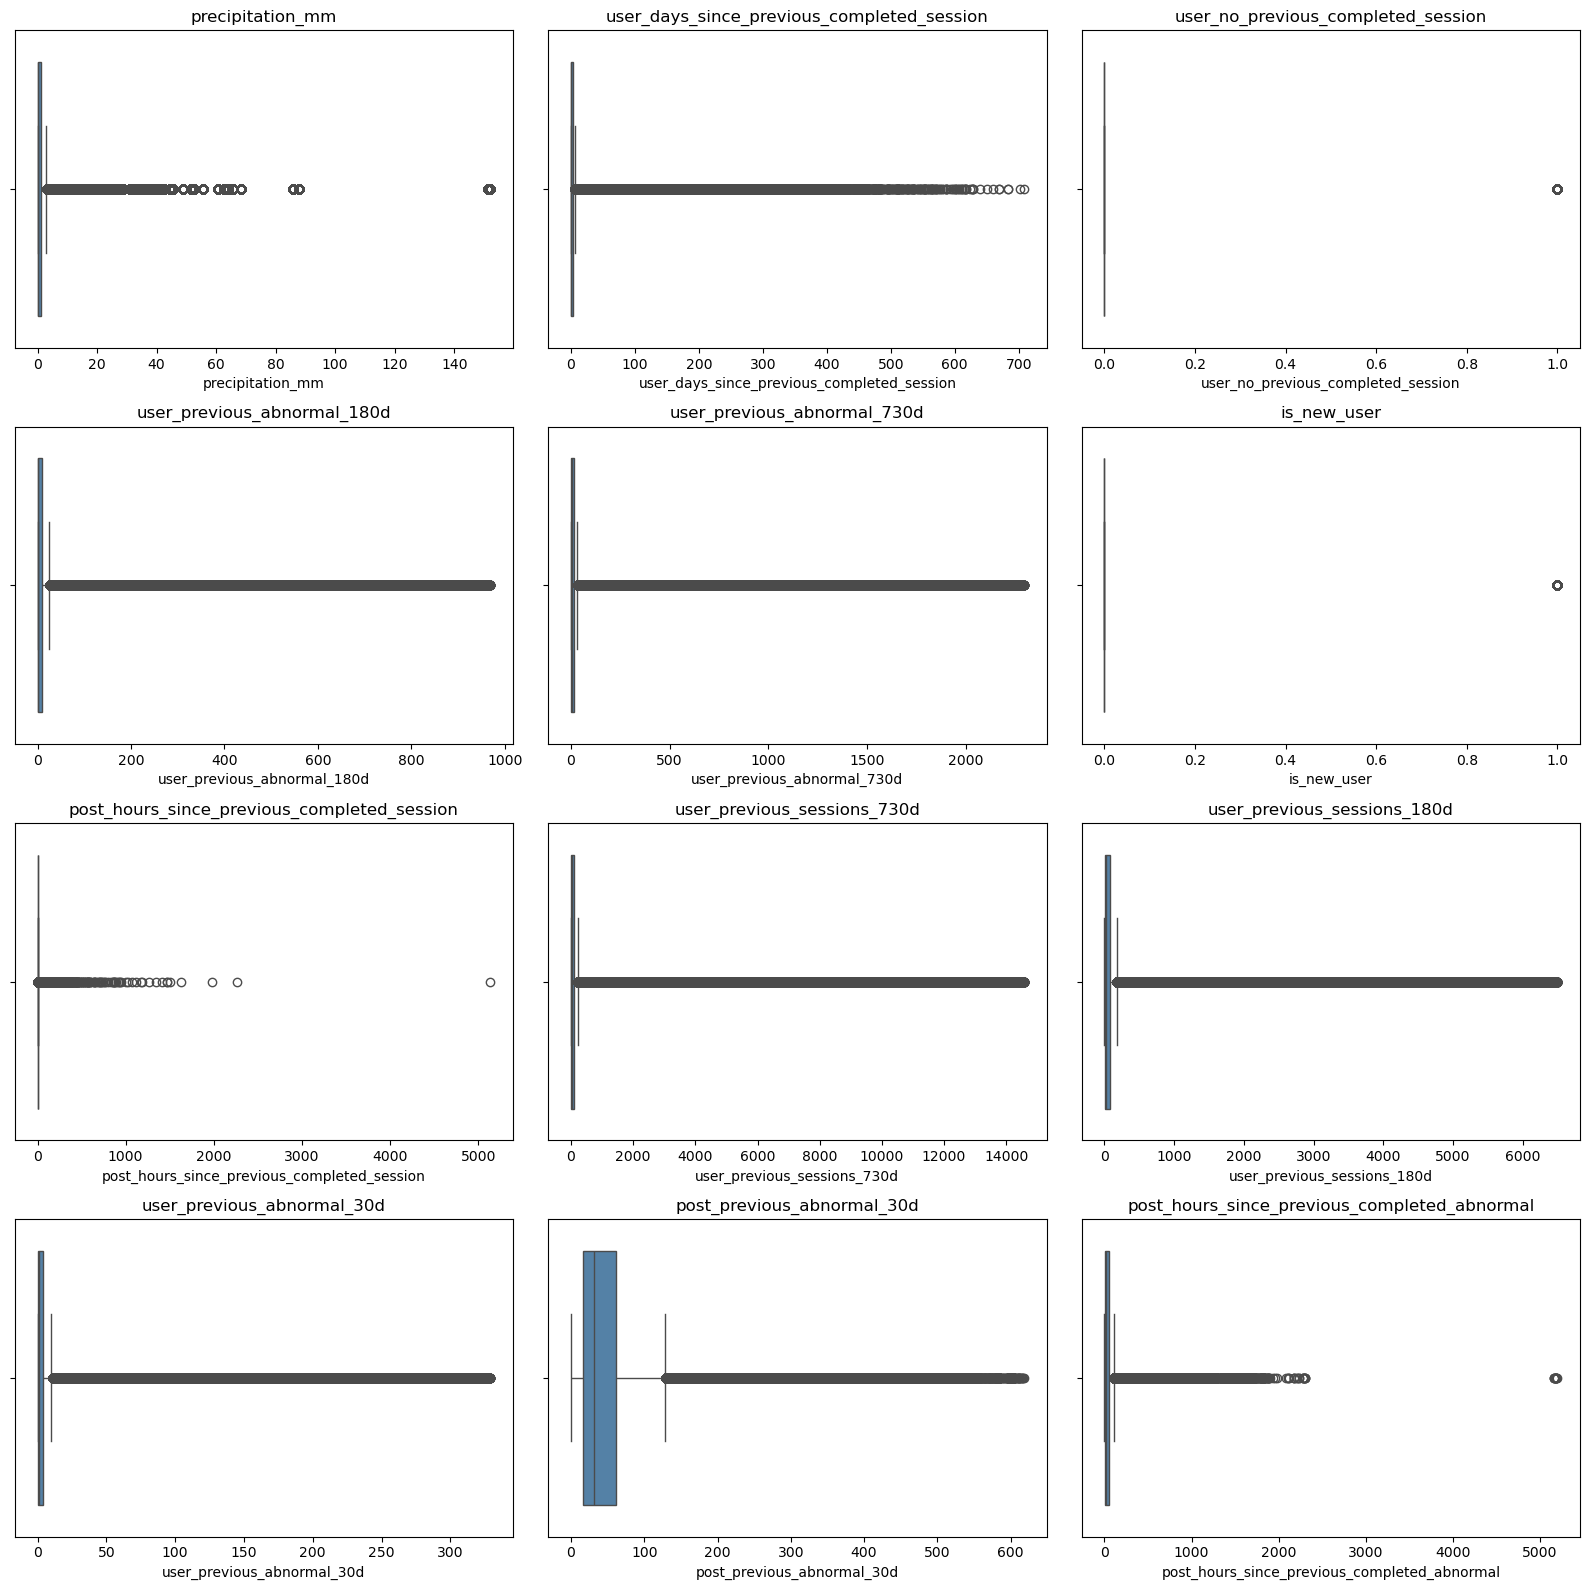

In [77]:
outlier_rows = []
for col in eda_numeric:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "variable": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percentage": mask.mean() * 100
    })

outlier_summary = (pd.DataFrame(outlier_rows)
                   .sort_values("outlier_percentage", ascending=False))
display(outlier_summary)

outlier_plot_cols = outlier_summary.head(12)["variable"].tolist()
fig, axes = plt.subplots(int(np.ceil(len(outlier_plot_cols) / 3)), 3,
                         figsize=(16, 4 * int(np.ceil(len(outlier_plot_cols) / 3))))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, outlier_plot_cols):
    sns.boxplot(x=df[col], ax=ax, color="steelblue")
    ax.set_title(col)
for ax in axes[len(outlier_plot_cols):]:
    ax.remove()
plt.tight_layout()
save_fig("outliers_boxplot")
plt.show()

A tabela indica quais variáveis apresentam mais observações fora dos limites do IQR. Estes valores podem representar variabilidade real, distribuições assimétricas ou situações que devem ser investigadas. Não são considerados erros automaticamente e não são removidos nesta fase.

**Como ler.** Cada gráfico mostra onde está a maioria dos valores e destaca, como pontos isolados, os valores muito acima ou abaixo do habitual (os «outliers»).

**O que significa para o negócio.** Estes valores extremos costumam corresponder a postos ou clientes muito ativos e não a erros. Retirá-los seria esconder precisamente os postos mais usados, que são os mais importantes para a operação. Por isso são mantidos.

## B.4. Variáveis categóricas
Nesta parte analisamos a relação de location_information, district_name e tariff_period com o target, mantendo as categorias raras e mostrando o número de sessões.

,sessions,abnormal_sessions,abnormal_rate
location_information,,,
Bus Station,60809,6104,10.037988
Park B,57294,4930,8.604740
Shopping Mall,56605,14453,25.533080
Expressway Service District C,50187,15256,30.398310
Government Agency,36551,4489,12.281470
Wholesale Market,34491,9153,26.537358
Technology Park,28867,2804,9.713514
Park A,27845,5644,20.269348
Tourist Attraction,23659,6215,26.269073


C:\Users\Isabel\AppData\Local\Temp\ipykernel_24728\3081048895.py:14: UserWarning: Glyph 9 (	) missing from current font.
  plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
c:\Users\Isabel\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


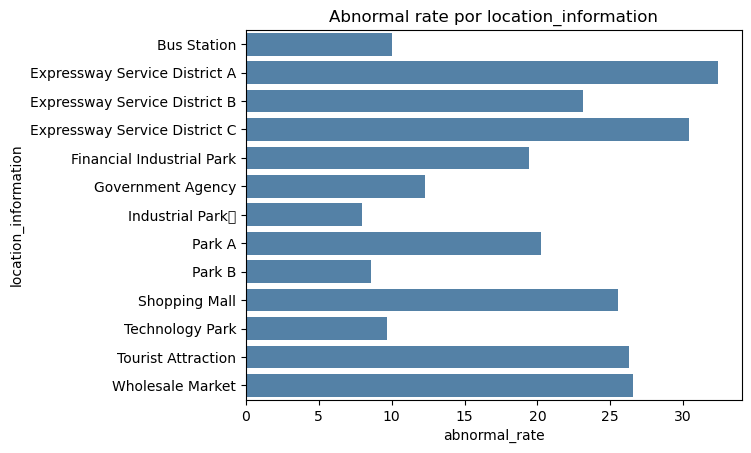

,sessions,abnormal_sessions,abnormal_rate
district_name,,,
Tongxiang,220923,32591,14.752199
Xiuzhou,148705,36652,24.647456
Nanhu,71449,12691,17.762320


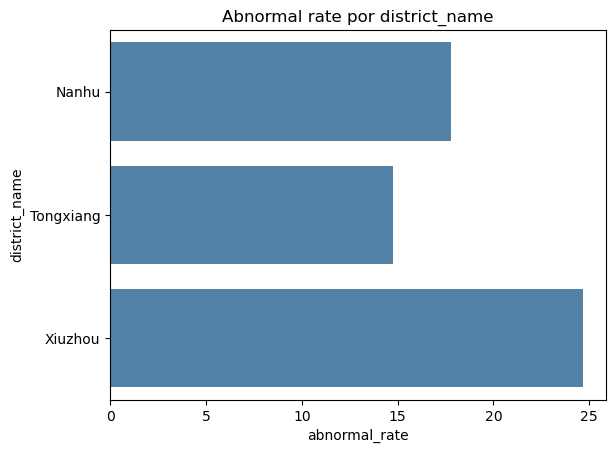

,sessions,abnormal_sessions,abnormal_rate
tariff_period,,,
peak_13_19,167118,31996,19.145753
off_peak_11_13,61760,12649,20.480894
peak_08_11,48977,8589,17.536803
off_peak_00_08,48633,8941,18.384636
sharp_19_21,48042,8043,16.741601
off_peak_22_24,43704,7874,18.016658
peak_21_22,22843,3842,16.819157


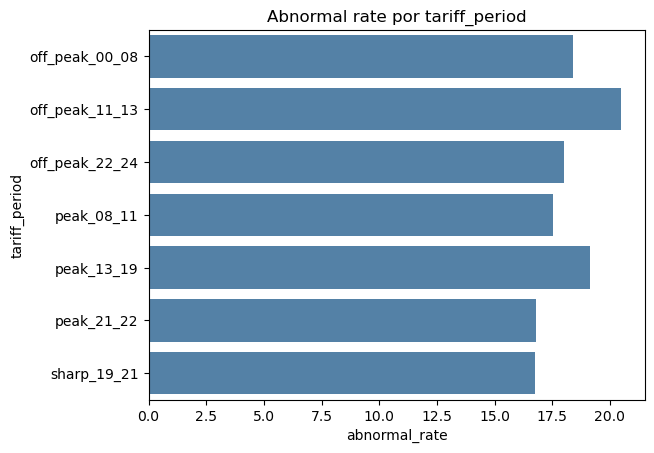

In [78]:
categorical_focus = [c for c in ["location_information", "district_name", "tariff_period"] if c in df.columns]
for col in categorical_focus:
    summary = df.groupby(col, dropna=False)["is_abnormal"].agg(sessions="size", abnormal_sessions="sum", abnormal_rate="mean")
    summary["abnormal_rate"] *= 100
    display(summary.sort_values("sessions", ascending=False))
    sns.barplot(data=summary.reset_index(), y=col, x="abnormal_rate", color="steelblue")
    plt.title(f"Abnormal rate por {col}")
    save_fig(f"abnormal_rate_{col}")
    plt.show()

As categorias com abnormal rates diferentes apresentam uma associação observada com o target. As categorias com poucas sessões produzem estimativas menos estáveis. Não são eliminadas nem codificadas.

**O que significa para o negócio.** Mostra em que locais e períodos tarifários há proporcionalmente mais falhas, ou seja, onde faz mais sentido concentrar inspeções e manutenção. Cuidado com os locais com poucas sessões: uma taxa alta pode ser apenas azar e não um problema real. Esta análise mostra onde há mais falhas, não porque é que há.

## B.5. Relação entre grupos de variáveis e o target
Comparamos os grupos de histórico do charging post e do utilizador. Estas variáveis representam informação disponível no início da sessão e podem revelar diferenças entre sessões normais e anormais.

In [79]:
feature_groups = {
    "Post history": [c for c in df.columns if c.startswith("post_")],
    "User history": [c for c in df.columns if c.startswith("user_")] + ["is_new_user"]
}
for group, cols in feature_groups.items():
    cols = [c for c in cols if c in df.columns]
    print(group)
    display(df.groupby("is_abnormal")[cols].mean().T)

Post history


is_abnormal,0,1
post_previous_sessions_1d,10.595387,12.773781
post_previous_abnormal_1d,1.515229,6.132509
post_previous_abnormal_rate_1d,0.157641,0.339057
post_previous_sessions_7d,70.029846,76.138904
post_previous_abnormal_7d,10.335284,29.455489
post_previous_abnormal_rate_7d,0.148154,0.336754
post_previous_sessions_30d,287.467922,292.562392
post_previous_abnormal_30d,44.554244,93.861523
post_previous_abnormal_rate_30d,0.155983,0.305385
post_hours_since_previous_completed_session,2.647400,3.013712


User history


is_abnormal,0,1
user_previous_sessions_30d,57.947500,45.947323
user_previous_abnormal_30d,8.520353,9.775917
user_previous_abnormal_rate_30d,0.175938,0.262134
user_previous_sessions_180d,192.811003,149.165951
user_previous_abnormal_180d,31.388029,28.738997
user_previous_abnormal_rate_180d,0.174127,0.256947
user_previous_sessions_730d,368.593215,285.541460
user_previous_abnormal_730d,58.908983,50.862499
user_previous_abnormal_rate_730d,0.174784,0.256307
user_days_since_previous_completed_session,8.426595,7.479419


Quando as médias ou medianas diferem entre as classes, o grupo apresenta comportamentos distintos e poderá ser relevante. Esta comparação não faz seleção de features nem permite afirmar causalidade.

**O que significa para o negócio.** Compara-se o «perfil médio» de uma sessão que falhou com o de uma sessão que correu bem. Se o histórico do posto ou do cliente é diferente nos dois casos, esses indicadores podem funcionar como sinais de alerta antes de o carregamento começar.

## B.6. District, Location e Charging Post
Analisamos a cardinalidade, as relações de pertença, o volume de sessões e a abnormal rate. Os charging posts com poucas observações exigem cautela.

In [80]:
for col in ["district_name", "location_information", "charging_post_id"]:
    print(col, df[col].nunique(dropna=False), "valores distintos")
display(df.groupby("district_name")["location_information"].nunique())
display(df.groupby("location_information")["charging_post_id"].nunique())
print("Post pertence a uma location:", df.groupby("charging_post_id")["location_information"].nunique().max() == 1)
print("Location pertence a um district:", df.groupby("location_information")["district_name"].nunique().max() == 1)
for col in ["district_name", "location_information", "charging_post_id"]:
    out = df.groupby(col)["is_abnormal"].agg(sessions="size", abnormal_rate="mean")
    out["abnormal_rate"] *= 100
    display(out.sort_values("sessions", ascending=False).head(20))

district_name 3 valores distintos
location_information 13 valores distintos
charging_post_id 92 valores distintos


district_name
Nanhu        3
Tongxiang    5
Xiuzhou      5
Name: location_information, dtype: int64

location_information
Bus Station                      8
Expressway Service District A    4
Expressway Service District B    4
Expressway Service District C    8
Financial Industrial Park        8
Government Agency                8
Industrial Park\t                8
Park A                           8
Park B                           8
Shopping Mall                    8
Technology Park                  4
Tourist Attraction               8
Wholesale Market                 8
Name: charging_post_id, dtype: int64

Post pertence a uma location: True
Location pertence a um district: True


,sessions,abnormal_rate
district_name,,
Tongxiang,220923,14.752199
Xiuzhou,148705,24.647456
Nanhu,71449,17.762320


,sessions,abnormal_rate
location_information,,
Bus Station,60809,10.037988
Park B,57294,8.604740
Shopping Mall,56605,25.533080
Expressway Service District C,50187,30.398310
Government Agency,36551,12.281470
Wholesale Market,34491,26.537358
Technology Park,28867,9.713514
Park A,27845,20.269348
Tourist Attraction,23659,26.269073


,sessions,abnormal_rate
charging_post_id,,
77,8728,28.242438
46,8097,5.384710
54,7990,26.645807
59,7858,9.035378
79,7854,34.288261
52,7842,5.024229
53,7659,5.431518
56,7626,9.179124
21,7619,31.053944


A consistência das pertenças mostra se existe uma hierarquia estável. Os volumes e as abnormal rates descrevem diferenças de utilização, mas não provam que uma location ou um charging post cause anomalias.

**O que significa para o negócio.** A rede está organizada em níveis: distrito, localização e posto. Saber isto diz a que nível se pode agir (por exemplo, enviar uma equipa a uma localização ou reparar um posto específico). Os números por volume mostram onde há mais movimento e, portanto, onde uma falha afeta mais clientes.

## B.7. Análise de correlação
Calculamos uma matriz apenas para as variáveis numéricas de histórico e ambientais, excluindo identificadores e variáveis posteriores à sessão. Correlação não significa causalidade nem determina a remoção de variáveis.

**Como ler.** Cada quadrado indica se duas variáveis «andam juntas»: perto de +1, quando uma sobe a outra também sobe; perto de -1, quando uma sobe a outra desce; perto de 0, não há relação clara.

**O que significa para o negócio.** Duas variáveis que andam sempre juntas dão praticamente a mesma informação (por exemplo, o número de falhas e a percentagem de falhas do mesmo posto). Isto ajuda a perceber quais as informações que se repetem e quais as que realmente acrescentam algo. A linha `is_abnormal` mostra quais as variáveis mais ligadas às falhas, mas só deteta relações simples e não explica a causa.

,post_previous_sessions_1d,post_previous_abnormal_1d,post_previous_abnormal_rate_1d,post_previous_sessions_7d,post_previous_abnormal_7d,post_previous_abnormal_rate_7d,post_previous_sessions_30d,post_previous_abnormal_30d,post_previous_abnormal_rate_30d,post_hours_since_previous_completed_session,...,user_no_previous_completed_session,user_days_since_previous_completed_abnormal,user_no_previous_completed_abnormal,user_active_sessions_at_start,is_new_user,temperature,relative_humidity,precipitation_mm,electricity_price,is_abnormal
post_previous_sessions_1d,1.000000,0.646801,0.301353,0.788516,0.497633,0.185250,0.696470,0.445817,0.119599,-0.159872,...,-0.039252,-0.035614,-0.065078,-0.006109,-0.039164,0.114629,-0.064283,-0.003122,-0.007440,0.129746
post_previous_abnormal_1d,0.646801,1.000000,0.848843,0.419314,0.752062,0.631096,0.287843,0.583567,0.487521,-0.047826,...,0.024038,-0.067120,-0.030661,-0.011349,0.023319,0.094627,-0.015878,0.007691,-0.000473,0.374288
post_previous_abnormal_rate_1d,0.301353,0.848843,1.000000,0.147684,0.681995,0.777721,0.037576,0.527585,0.624617,0.004243,...,0.054219,-0.086431,-0.015262,-0.012689,0.053083,0.053442,0.006642,0.012918,-0.004274,0.445734
post_previous_sessions_7d,0.788516,0.419314,0.147684,1.000000,0.575638,0.156205,0.898664,0.522467,0.080130,-0.162730,...,-0.033724,-0.020925,-0.057242,-0.008538,-0.033535,0.132995,-0.056147,-0.000098,-0.002100,0.067794
post_previous_abnormal_7d,0.497633,0.752062,0.681995,0.575638,1.000000,0.806959,0.413540,0.801776,0.635334,-0.048117,...,0.056396,-0.063255,-0.001159,-0.013599,0.055455,0.118979,-0.006045,0.014954,0.001565,0.349289
post_previous_abnormal_rate_7d,0.185250,0.631096,0.777721,0.156205,0.806959,1.000000,0.037740,0.650322,0.824643,0.016536,...,0.087736,-0.085343,0.015945,-0.014088,0.086425,0.053684,0.016541,0.013985,-0.005387,0.429657
post_previous_sessions_30d,0.696470,0.287843,0.037576,0.898664,0.413540,0.037740,1.000000,0.536907,0.036775,-0.156780,...,-0.038670,-0.006209,-0.056754,-0.014269,-0.038303,0.105865,-0.058821,0.003355,-0.002020,0.014292
post_previous_abnormal_30d,0.445817,0.583567,0.527585,0.522467,0.801776,0.650322,0.536907,1.000000,0.767154,-0.052155,...,0.080919,-0.062118,0.021588,-0.011676,0.079992,0.127122,0.001291,0.019651,0.000822,0.286230
post_previous_abnormal_rate_30d,0.119599,0.487521,0.624617,0.080130,0.635334,0.824643,0.036775,0.767154,1.000000,0.028365,...,0.113342,-0.087601,0.040485,-0.009858,0.111835,0.054569,0.026432,0.013766,-0.004675,0.368977
post_hours_since_previous_completed_session,-0.159872,-0.047826,0.004243,-0.162730,-0.048117,0.016536,-0.156780,-0.052155,0.028365,1.000000,...,0.030184,0.006666,0.024054,-0.002135,0.029960,-0.040341,0.005344,-0.005376,-0.013029,0.008773


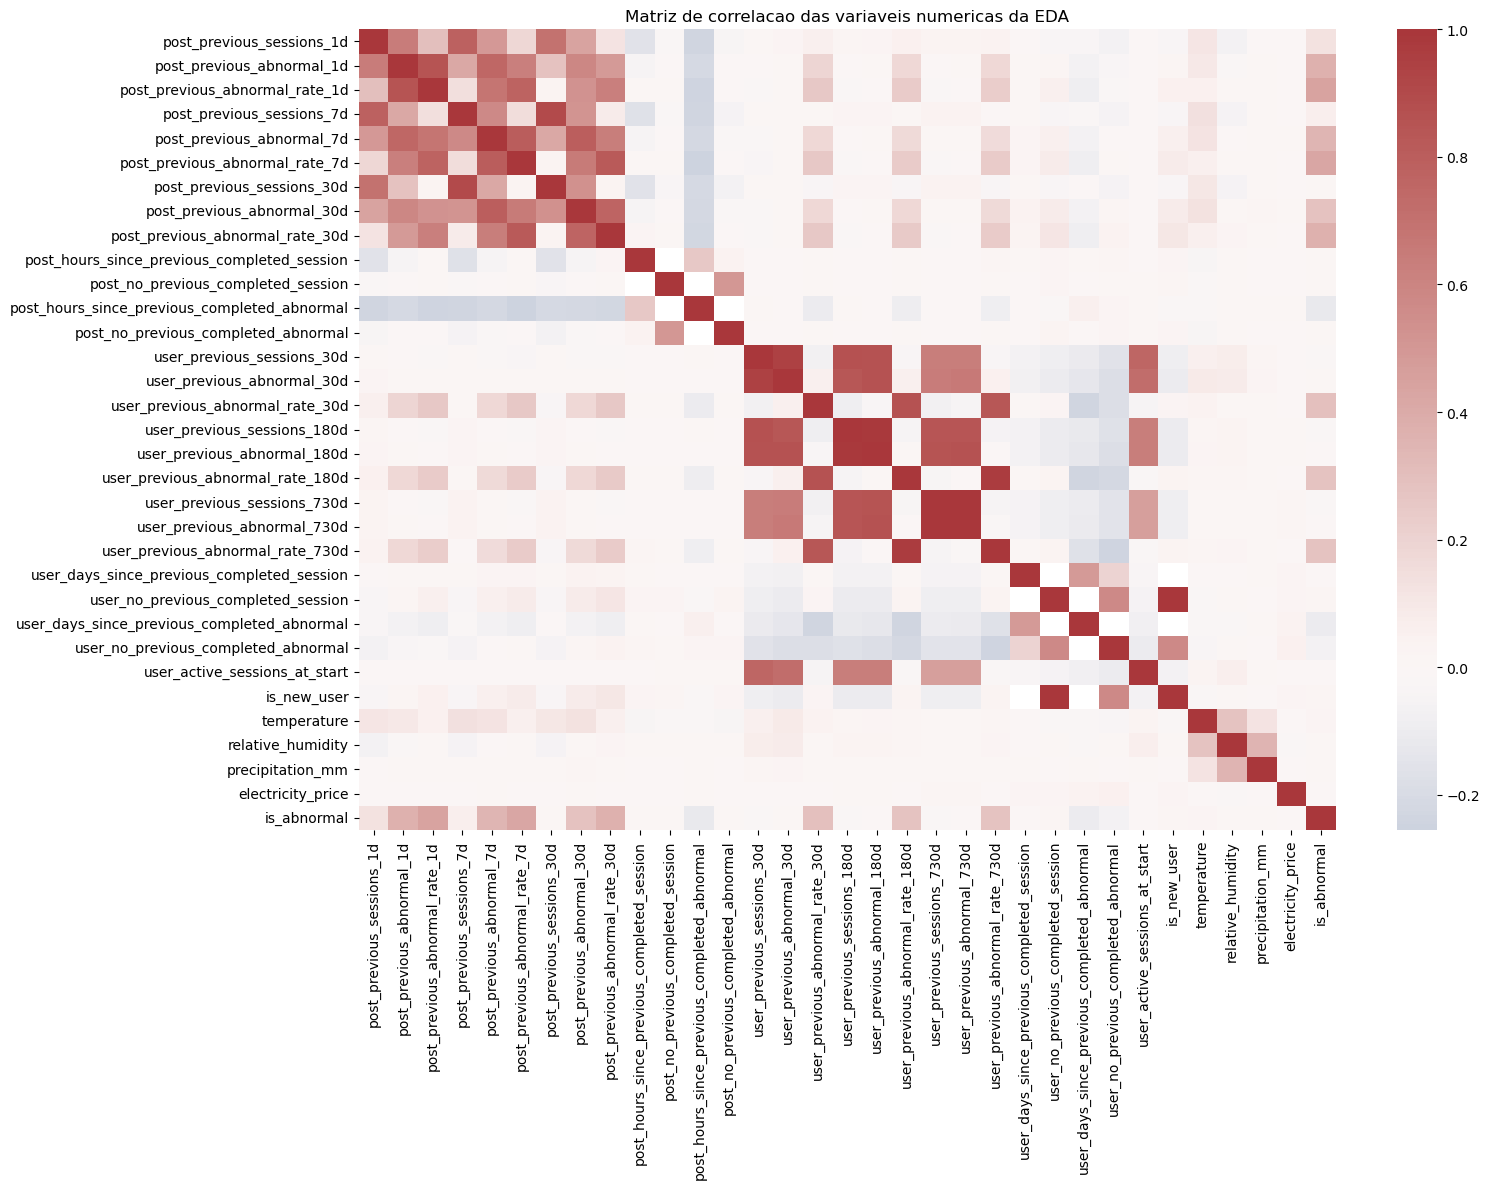

In [81]:
corr_cols = [c for c in eda_numeric + ["is_abnormal"] if c in df.columns]
corr_matrix = df[corr_cols].corr()
display(corr_matrix)
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, cmap="vlag", center=0)
plt.title("Matriz de correlacao das variaveis numericas da EDA")
plt.tight_layout()
save_fig("correlation_matrix")
plt.show()

# Parte C. Análise temporal e drift

## C.1. Preparação temporal
Criamos variáveis auxiliares para a EDA: ano, mês, semana, dia, dia da semana e hora.

In [82]:
for col in ["order_creation_time", "start_time"]:
    if not pd.api.types.is_datetime64_any_dtype(df[col]):
        df[col] = pd.to_datetime(df[col], errors="coerce")
session_time = df["start_time"].fillna(df["order_creation_time"])
df["eda_year"] = session_time.dt.year
df["eda_month"] = session_time.dt.to_period("M").astype(str)
df["eda_week"] = session_time.dt.to_period("W").astype(str)
df["eda_day"] = session_time.dt.date
df["eda_day_of_week"] = session_time.dt.day_name()
df["eda_hour"] = session_time.dt.hour
print(df[["order_creation_time", "start_time", "eda_month", "eda_day_of_week", "eda_hour"]].head())

  order_creation_time          start_time eda_month eda_day_of_week  eda_hour
0 2019-12-31 21:26:58 2019-12-31 21:27:03   2019-12         Tuesday        21
1 2019-12-31 21:50:58 2019-12-31 21:50:56   2019-12         Tuesday        21
2 2019-12-31 22:19:34 2019-12-31 22:12:46   2019-12         Tuesday        22
3 2019-12-31 22:37:24 2019-12-31 22:38:55   2019-12         Tuesday        22
4 2019-12-31 23:32:28 2019-12-31 23:06:44   2019-12         Tuesday        23


## C.2. Volume de sessões ao longo do tempo
A contagem por mês e por semana identifica períodos de maior ou menor atividade, sazonalidade aparente ou alterações abruptas, sem inventar causas.

,sessions
eda_month,
2019-12,17
2020-01,6217
2020-02,1391
2020-03,6392
2020-04,11136
2020-05,15033
2020-06,17513
2020-07,22032
2020-08,25562


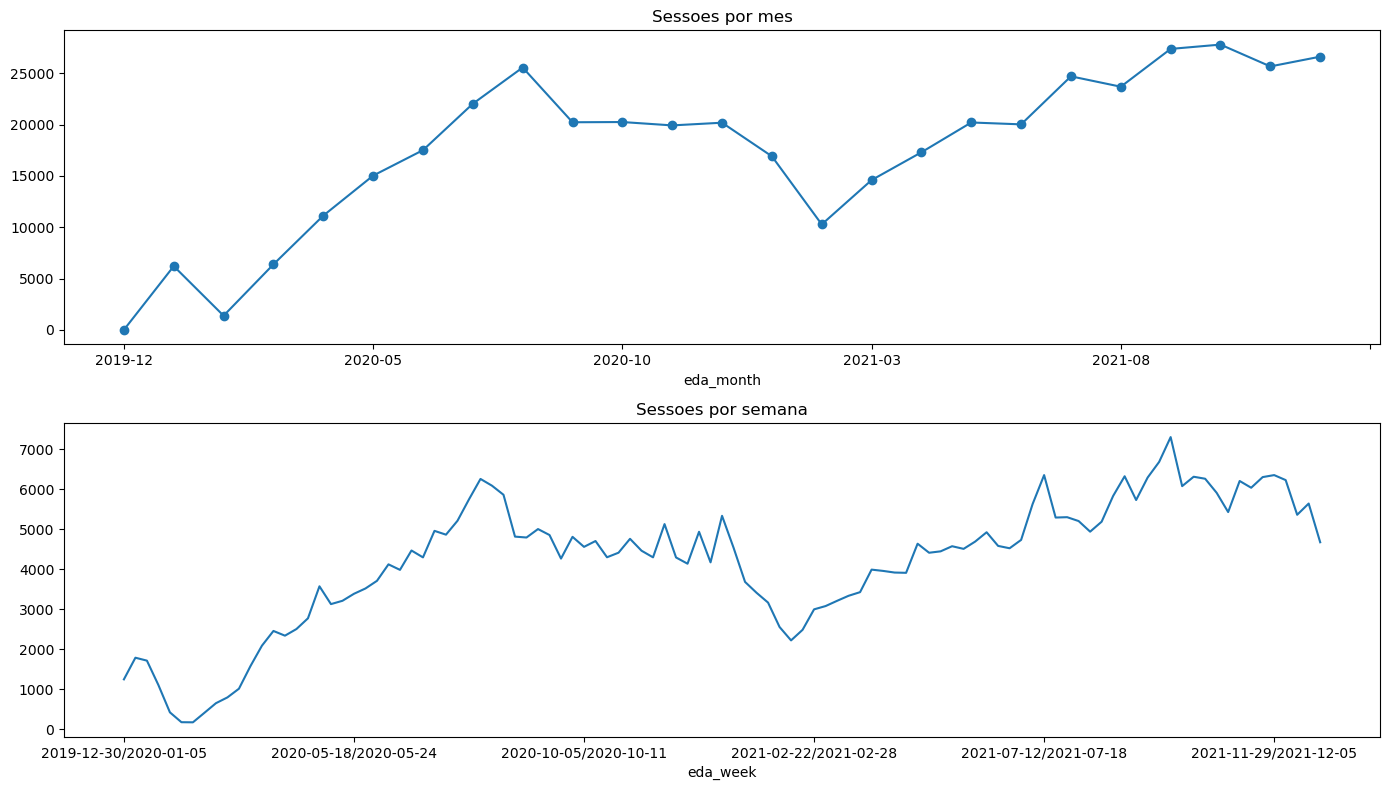

In [83]:
monthly_volume = df.groupby("eda_month").size().rename("sessions")
weekly_volume = df.groupby("eda_week").size().rename("sessions")
display(monthly_volume.to_frame())
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
monthly_volume.plot(ax=axes[0], marker="o", title="Sessoes por mes")
weekly_volume.plot(ax=axes[1], title="Sessoes por semana")
plt.tight_layout()
save_fig("sessions_monthly_weekly")
plt.show()

Os picos e vales representam alterações reais no volume observado. Os períodos com poucas sessões devem ser interpretados com cuidado e a variação não permite inferir a sua causa.

**O que significa para o negócio.** O volume mede a procura. Se sobe de forma contínua, a rede está a crescer e a ser mais usada, o que exige mais capacidade e mais manutenção. Quedas bruscas ou períodos quase vazios podem ser paragens do serviço ou falhas na recolha dos dados. Os meses com poucas sessões dão percentagens pouco fiáveis, por isso não devem ser comparados diretamente com meses movimentados.

## C.3. Abnormal rate ao longo do tempo
Calculamos mensalmente abnormal_rate = sessões anormais / sessões totais, mostrando também o volume total.

,sessions,abnormal_sessions,abnormal_rate
eda_month,,,
2019-12,17,5,29.411765
2020-01,6217,1555,25.012064
2020-02,1391,366,26.312006
2020-03,6392,1584,24.780976
2020-04,11136,2456,22.054598
2020-05,15033,2884,19.184461
2020-06,17513,2801,15.993833
2020-07,22032,4015,18.223493
2020-08,25562,5128,20.061028


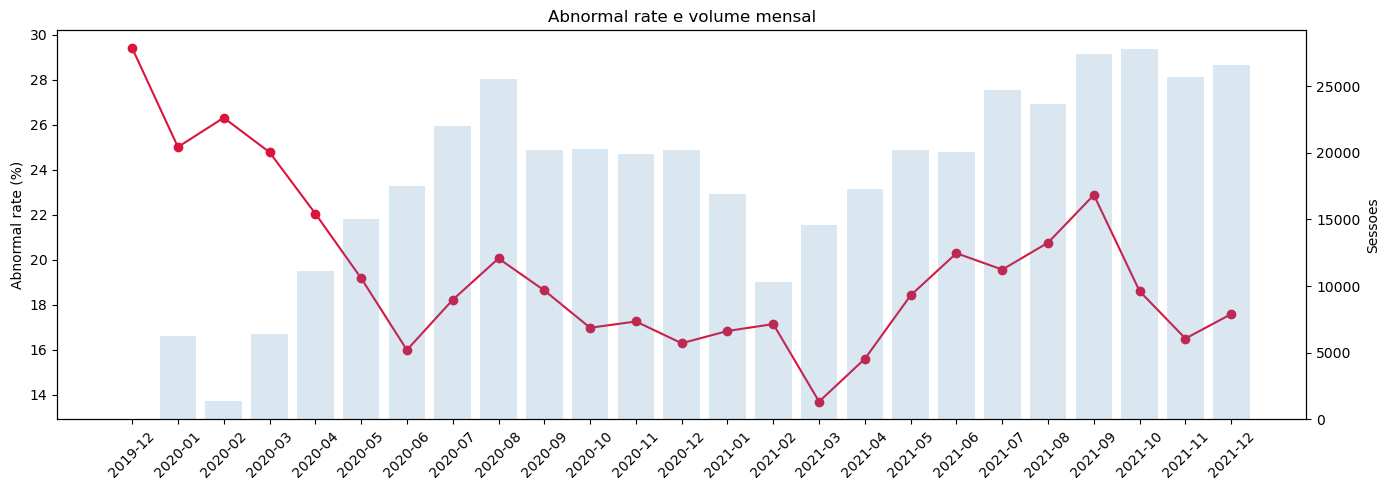

In [84]:
monthly_rate = df.groupby("eda_month")["is_abnormal"].agg(sessions="size", abnormal_sessions="sum", abnormal_rate="mean")
monthly_rate["abnormal_rate"] *= 100
display(monthly_rate)
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly_rate.index, monthly_rate["abnormal_rate"], marker="o", color="crimson")
ax1.set_ylabel("Abnormal rate (%)")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.bar(monthly_rate.index, monthly_rate["sessions"], alpha=.2, color="steelblue")
ax2.set_ylabel("Sessoes")
plt.title("Abnormal rate e volume mensal")
plt.tight_layout()
save_fig("abnormal_rate_monthly")
plt.show()

A estabilidade ou variação da abnormal rate deve ser avaliada juntamente com o volume. Pequenas diferenças em meses com poucas sessões não são evidência suficiente de temporal drift.

**Em termos simples.** A linha vermelha mostra, mês a mês, a percentagem de sessões que falharam; as barras azuis mostram quantas sessões houve.

**O que significa para o negócio.** É o «termómetro» da qualidade do serviço: se a linha sobe, mais clientes estão a ter problemas. Se sobe quando há muitas sessões, é um sinal sério; se sobe num mês com muito poucas sessões, pode ser só ruído. Se a taxa muda muito ao longo do tempo, o que se aprendeu com o passado pode não servir no futuro, e é por isso que os modelos têm de ser testados em períodos mais recentes do que aqueles em que foram treinados.

### Média móvel diária da abnormal rate
Taxa calculada como soma de anómalas / soma de sessões numa janela de 7 e 30 dias, comparada com a média global. É mais fina do que a vista mensal e mostra quando a mudança acontece.

**O que é uma média móvel (em termos simples).** Os valores de cada dia variam muito por acaso. Para ver a tendência, em vez de olhar para um só dia, olha-se para a média dos últimos 7 dias (ou 30 dias) e repete-se todos os dias. É como acompanhar a média das notas dos últimos testes em vez de uma só nota: os altos e baixos pontuais desaparecem e vê-se a direção geral.

- A linha de 7 dias reage mais depressa.
- A linha de 30 dias é mais estável e mostra a tendência de fundo.
- A linha tracejada é a taxa média de todo o período, para comparação.

**O que significa para o negócio.** Quando a linha sobe acima da média e lá fica, o serviço está a piorar, e é possível ver quando começou. A linha de 7 dias serve para alertas rápidos à operação; a de 30 dias, para relatórios de tendência à gestão.

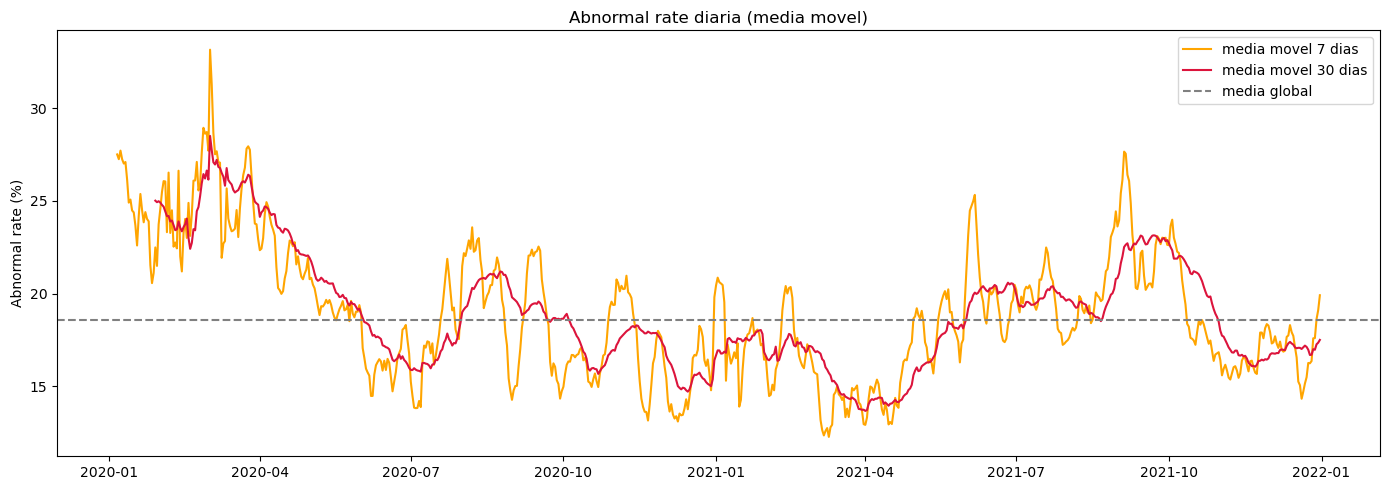

In [85]:
daily = df.groupby("eda_day")["is_abnormal"].agg(sessions="size", abnormal="sum")
daily.index = pd.to_datetime(daily.index)
daily = daily.asfreq("D", fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
for window, color in [(7, "orange"), (30, "crimson")]:
    rate = daily["abnormal"].rolling(window).sum() / daily["sessions"].rolling(window).sum() * 100
    ax.plot(rate.index, rate, color=color, label=f"media movel {window} dias")
ax.axhline(df["is_abnormal"].mean() * 100, color="grey", ls="--", label="media global")
ax.set_ylabel("Abnormal rate (%)")
ax.set_title("Abnormal rate diaria (media movel)")
ax.legend()
plt.tight_layout()
save_fig("abnormal_rate_rolling")
plt.show()

### Média móvel diária da abnormal rate
Taxa calculada como soma de anómalas / soma de sessões numa janela de 7 e 30 dias, comparada com a média global. É mais fina do que a vista mensal e mostra quando a mudança acontece.

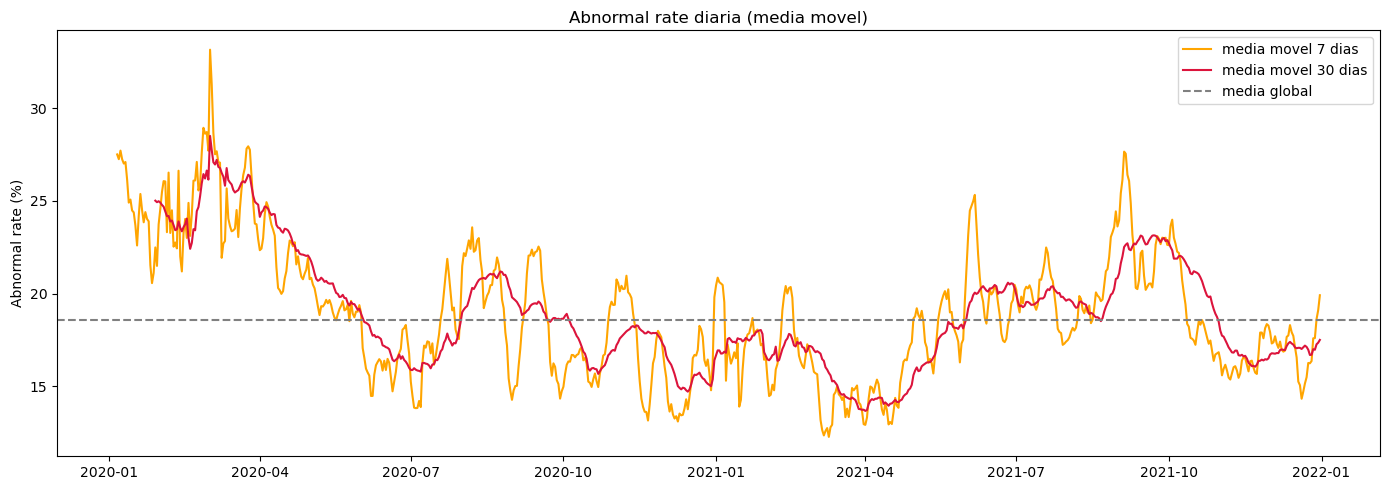

In [86]:
daily = df.groupby("eda_day")["is_abnormal"].agg(sessions="size", abnormal="sum")
daily.index = pd.to_datetime(daily.index)
daily = daily.asfreq("D", fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
for window, color in [(7, "orange"), (30, "crimson")]:
    rate = daily["abnormal"].rolling(window).sum() / daily["sessions"].rolling(window).sum() * 100
    ax.plot(rate.index, rate, color=color, label=f"media movel {window} dias")
ax.axhline(df["is_abnormal"].mean() * 100, color="grey", ls="--", label="media global")
ax.set_ylabel("Abnormal rate (%)")
ax.set_title("Abnormal rate diaria (media movel)")
ax.legend()
plt.tight_layout()
save_fig("abnormal_rate_rolling")
plt.show()


## C.4. Análise por hora, dia da semana e mês
Agregamos as sessões, as sessões anormais e a abnormal rate por hora, dia da semana e mês. A ordem dos dias é fixada de Monday a Sunday.

,sessions,abnormal_sessions,abnormal_rate
eda_hour,,,
0,11381,2190,19.242597
1,7012,1352,19.281232
2,5101,1001,19.623603
3,4548,853,18.755497
4,3969,755,19.022424
5,3876,710,18.317853
6,5670,968,17.072310
7,7076,1112,15.715093
8,9746,1621,16.632465


,sessions,abnormal_sessions,abnormal_rate
eda_day_of_week,,,
Monday,62064,11303,18.211846
Tuesday,61465,11245,18.294965
Wednesday,62093,11607,18.692928
Thursday,63220,12117,19.166403
Friday,65562,12371,18.869162
Saturday,64463,11984,18.590509
Sunday,62210,11307,18.175534


,sessions,abnormal_sessions,abnormal_rate
eda_month,,,
2019-12,17,5,29.411765
2020-01,6217,1555,25.012064
2020-02,1391,366,26.312006
2020-03,6392,1584,24.780976
2020-04,11136,2456,22.054598
2020-05,15033,2884,19.184461
2020-06,17513,2801,15.993833
2020-07,22032,4015,18.223493
2020-08,25562,5128,20.061028


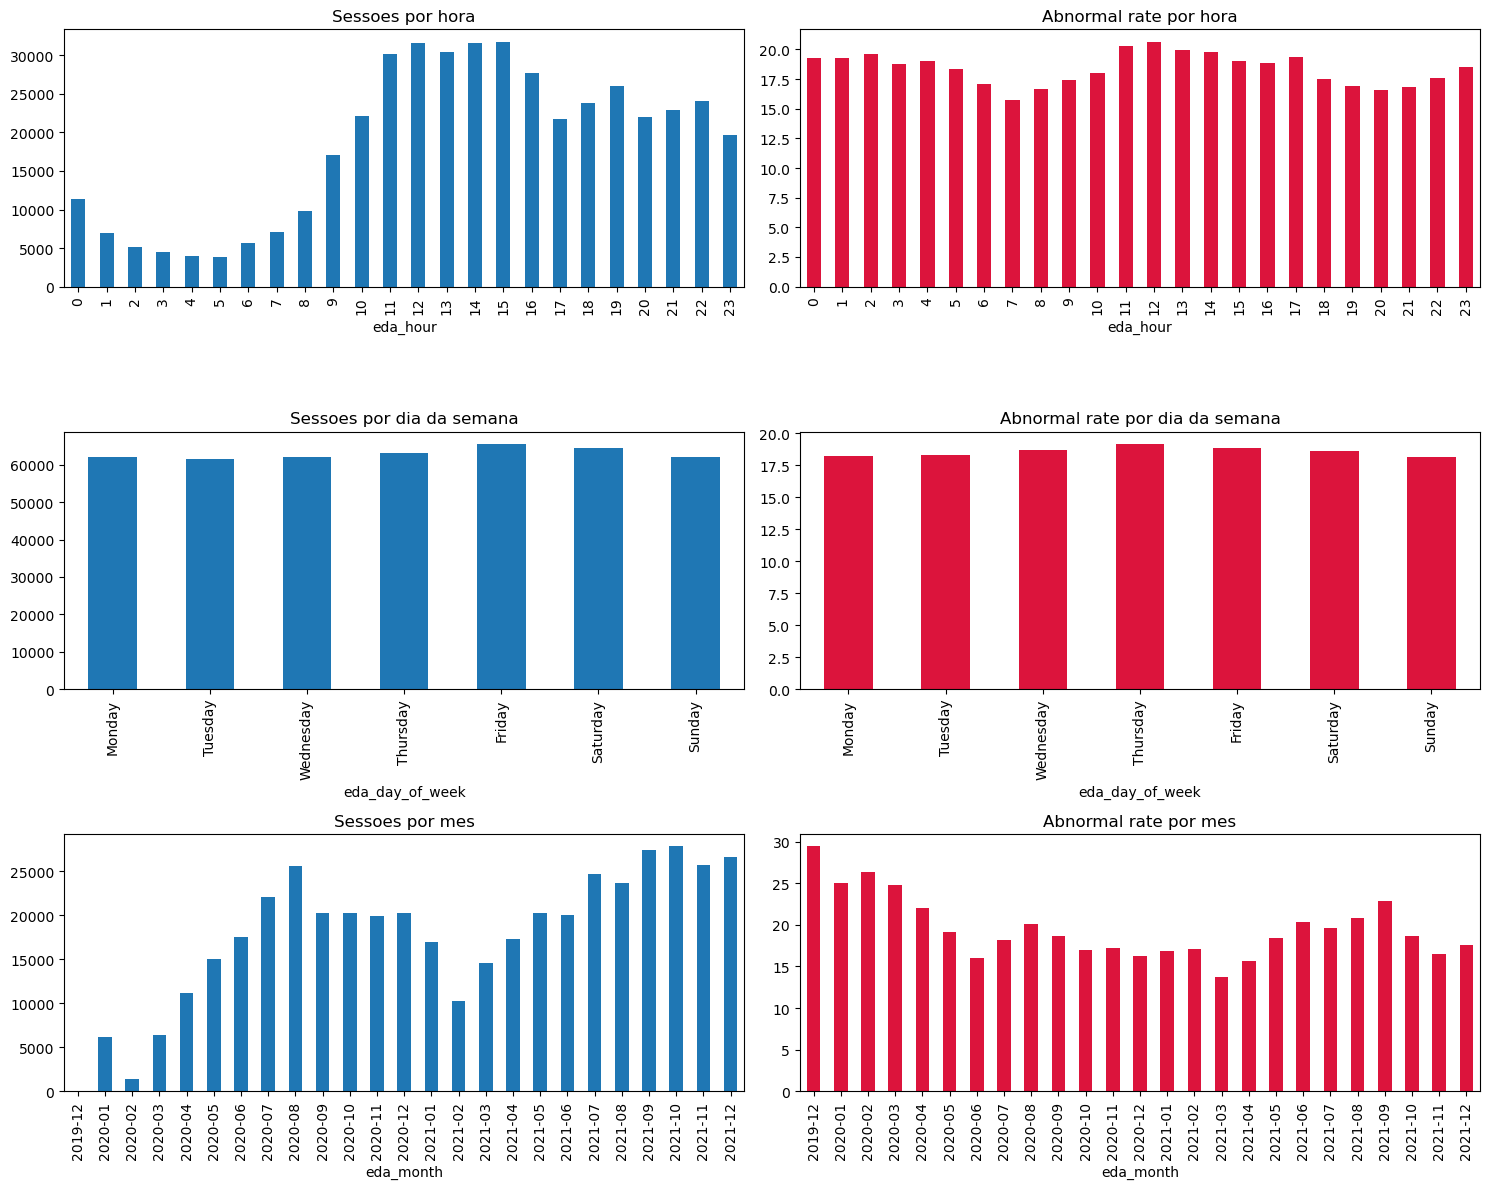

In [87]:
def temporal_summary(column):
    out = df.groupby(column)["is_abnormal"].agg(sessions="size", abnormal_sessions="sum", abnormal_rate="mean")
    out["abnormal_rate"] *= 100
    return out
hour_summary = temporal_summary("eda_hour")
day_summary = temporal_summary("eda_day_of_week").reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
month_summary = temporal_summary("eda_month")
display(hour_summary)
display(day_summary)
display(month_summary)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for row, summary, title in [(0, hour_summary, "hora"), (1, day_summary, "dia da semana"), (2, month_summary, "mes")]:
    summary["sessions"].plot(kind="bar", ax=axes[row, 0], title=f"Sessoes por {title}")
    summary["abnormal_rate"].plot(kind="bar", ax=axes[row, 1], color="crimson", title=f"Abnormal rate por {title}")
plt.tight_layout()
save_fig("hour_day_month_summary")
plt.show()

Os gráficos mostram os períodos com maior volume e as diferenças de abnormal rate. Qualquer padrão deve ser suportado pelo número de sessões; diferenças observacionais não demonstram causalidade.

**O que significa para o negócio.** Mostra quando os postos estão mais cheios e quando falham mais. É útil para decidir quando fazer manutenção (nas horas e dias de menos movimento, para incomodar menos clientes) e quando reforçar o apoio ao cliente (nas de mais movimento). As horas com poucas sessões podem ter percentagens enganadoras, por isso convém olhar sempre para o volume ao lado.

### Heatmaps hora × dia da semana
Volume e abnormal rate por combinação de dia da semana e hora, e abnormal rate por período tarifário e hora. As células com poucas sessões são menos fiáveis.

**Como ler.** É uma tabela com cores, como um mapa de calor: cada quadrado é uma combinação de dia da semana e hora, e quanto mais escura a cor, maior o valor (mais sessões ou mais falhas).

**O que significa para o negócio.** O primeiro mapa mostra os momentos de maior movimento (por exemplo, dias úteis face a fim de semana). O segundo mostra se há momentos em que se falha mais. O terceiro mostra se as falhas dependem do período tarifário (horas mais caras ou mais baratas). Os quadrados com poucas sessões têm cores pouco fiáveis.

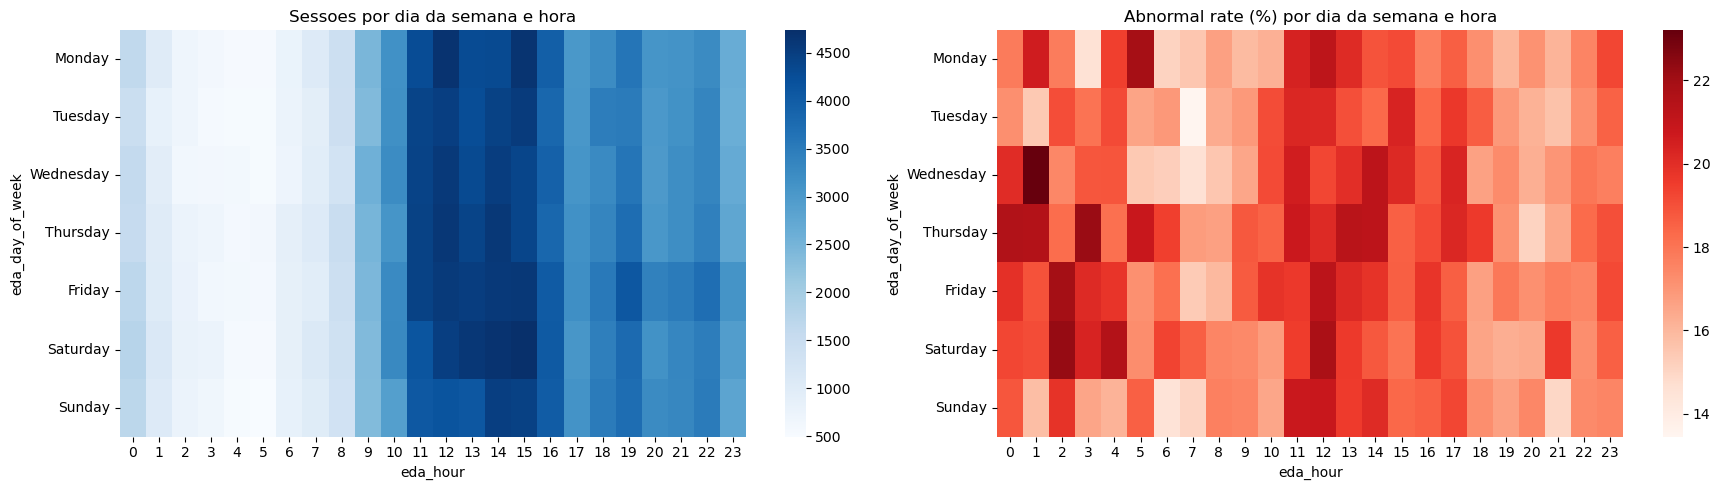

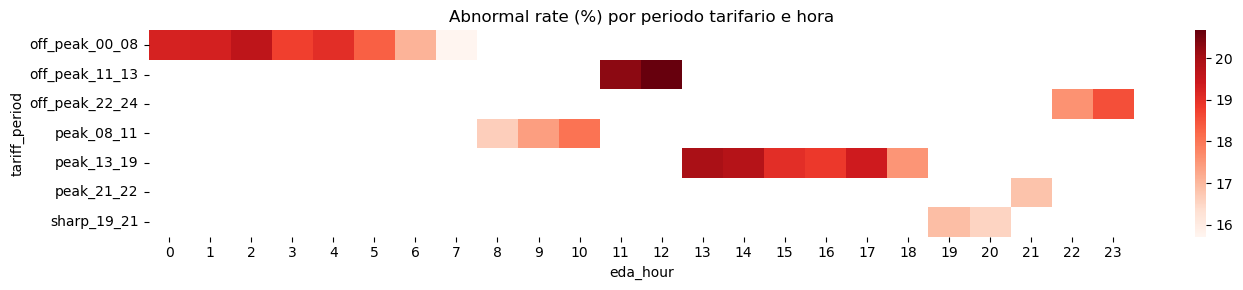

In [88]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
g = df.groupby(["eda_day_of_week", "eda_hour"])["is_abnormal"].agg(sessions="size", rate="mean")
volume_hm = g["sessions"].unstack().reindex(order)
rate_hm = g["rate"].unstack().reindex(order) * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.heatmap(volume_hm, cmap="Blues", ax=axes[0])
axes[0].set_title("Sessoes por dia da semana e hora")
sns.heatmap(rate_hm, cmap="Reds", ax=axes[1])
axes[1].set_title("Abnormal rate (%) por dia da semana e hora")
plt.tight_layout()
save_fig("heatmap_day_hour")
plt.show()

tariff_hm = (df.groupby(["tariff_period", "eda_hour"])["is_abnormal"].mean().unstack() * 100)
plt.figure(figsize=(14, 3))
sns.heatmap(tariff_hm, cmap="Reds", annot=False)
plt.title("Abnormal rate (%) por periodo tarifario e hora")
plt.tight_layout()
save_fig("heatmap_tariff_hour")
plt.show()

### Heatmaps hora × dia da semana
Volume e abnormal rate por combinação de dia da semana e hora, e abnormal rate por período tarifário e hora. As células com poucas sessões são menos fiáveis.

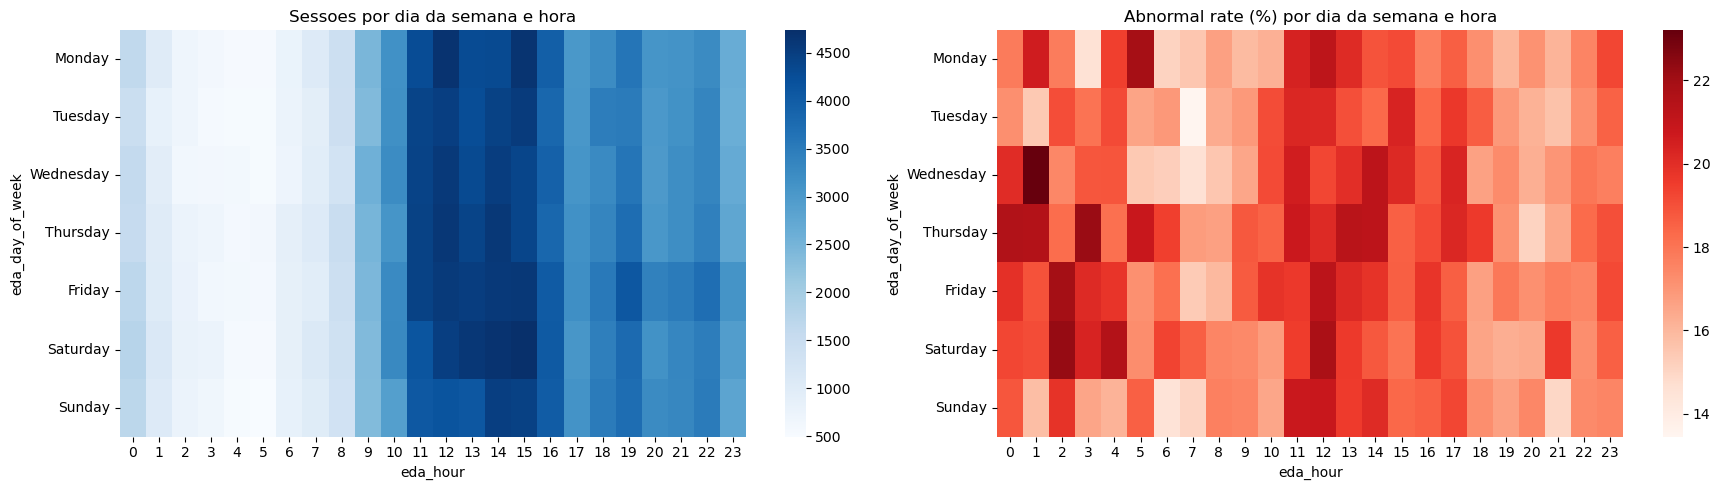

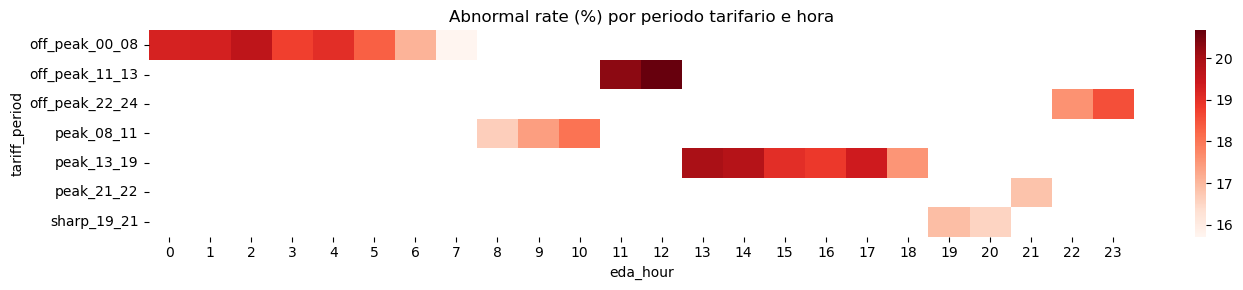

In [89]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
g = df.groupby(["eda_day_of_week", "eda_hour"])["is_abnormal"].agg(sessions="size", rate="mean")
volume_hm = g["sessions"].unstack().reindex(order)
rate_hm = g["rate"].unstack().reindex(order) * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.heatmap(volume_hm, cmap="Blues", ax=axes[0])
axes[0].set_title("Sessoes por dia da semana e hora")
sns.heatmap(rate_hm, cmap="Reds", ax=axes[1])
axes[1].set_title("Abnormal rate (%) por dia da semana e hora")
plt.tight_layout()
save_fig("heatmap_day_hour")
plt.show()

tariff_hm = (df.groupby(["tariff_period", "eda_hour"])["is_abnormal"].mean().unstack() * 100)
plt.figure(figsize=(14, 3))
sns.heatmap(tariff_hm, cmap="Reds", annot=False)
plt.title("Abnormal rate (%) por periodo tarifario e hora")
plt.tight_layout()
save_fig("heatmap_tariff_hour")
plt.show()


## C.5. Atividade dos utilizadores
Analisamos os utilizadores distintos por mês, as sessões por utilizador, is_new_user e user_active_sessions_at_start, para perceber se a população e a intensidade de utilização mudam.

,distinct_users
eda_month,
2019-12,16
2020-01,1963
2020-02,516
2020-03,1797
2020-04,2622
2020-05,3153
2020-06,3185
2020-07,3704
2020-08,4733


,sessions
count,56115.000000
mean,7.860233
std,74.159350
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,14584.000000


,sessions,abnormal_rate
is_new_user,,
0,384961,0.182870
1,56116,0.205574


,sessions,abnormal_rate
user_active_sessions_at_start,,
0,420500,0.185054
1,11718,0.238351
2,3799,0.164517
3,2026,0.139684
4,1153,0.138768
5,728,0.135989
6,448,0.129464
7,304,0.125000
8,197,0.152284


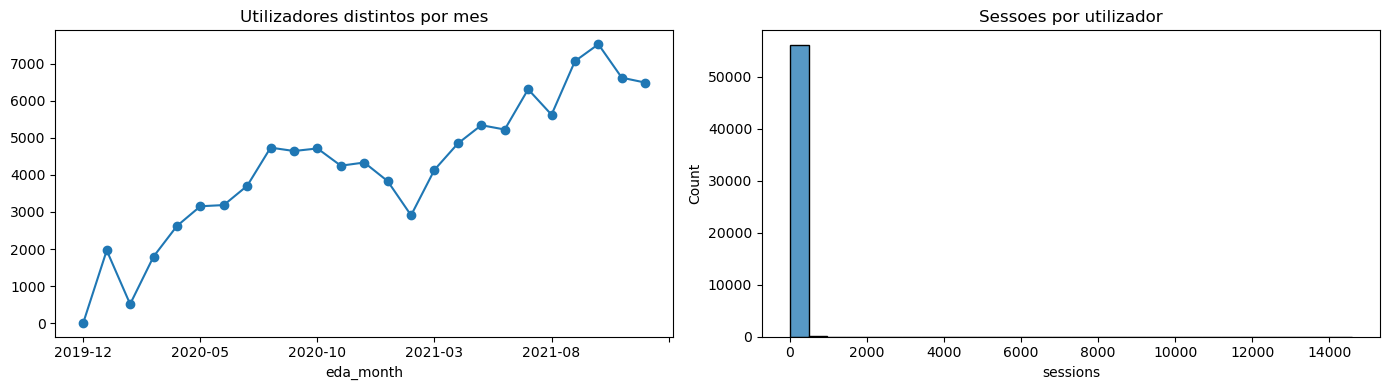

In [90]:
sessions_per_user = df.groupby("userid").size().rename("sessions")
users_by_month = df.groupby("eda_month")["userid"].nunique().rename("distinct_users")
display(users_by_month.to_frame())
display(sessions_per_user.describe().to_frame())
for col in ["is_new_user", "user_active_sessions_at_start"]:
    display(df.groupby(col)["is_abnormal"].agg(sessions="size", abnormal_rate="mean"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
users_by_month.plot(ax=axes[0], marker="o", title="Utilizadores distintos por mes")
sns.histplot(sessions_per_user, bins=30, ax=axes[1])
axes[1].set_title("Sessoes por utilizador")
plt.tight_layout()
save_fig("users_activity")
plt.show()

A evolução dos utilizadores distintos indica se a população observada muda. A distribuição de sessões mostra se a atividade está concentrada em poucos utilizadores. As relações com o target são descritivas.

**O que significa para o negócio.** Mostra se a base de clientes está a crescer e se a utilização está concentrada em poucos clientes muito frequentes ou espalhada por muitos. Se os clientes novos falham mais do que os habituais, pode haver dificuldade em usar o serviço (por exemplo, para iniciar um carregamento), o que sugere melhorar a experiência dos novos clientes.

## C.6. Atividade dos charging posts
Analisamos os charging posts ativos por mês, as sessões por post e a abnormal rate por post. Os posts com poucas observações são mantidos, mas não sustentam conclusões fortes.

,active_posts
eda_month,
2019-12,17
2020-01,92
2020-02,83
2020-03,92
2020-04,92
2020-05,92
2020-06,91
2020-07,92
2020-08,92


,sessions
count,92.000000
mean,4794.315217
std,2157.846107
min,797.000000
25%,2957.500000
50%,4368.000000
75%,7064.750000
max,8728.000000


,sessions,abnormal_rate
charging_post_id,,
77,8728,28.242438
46,8097,5.384710
54,7990,26.645807
59,7858,9.035378
79,7854,34.288261
52,7842,5.024229
53,7659,5.431518
56,7626,9.179124
21,7619,31.053944


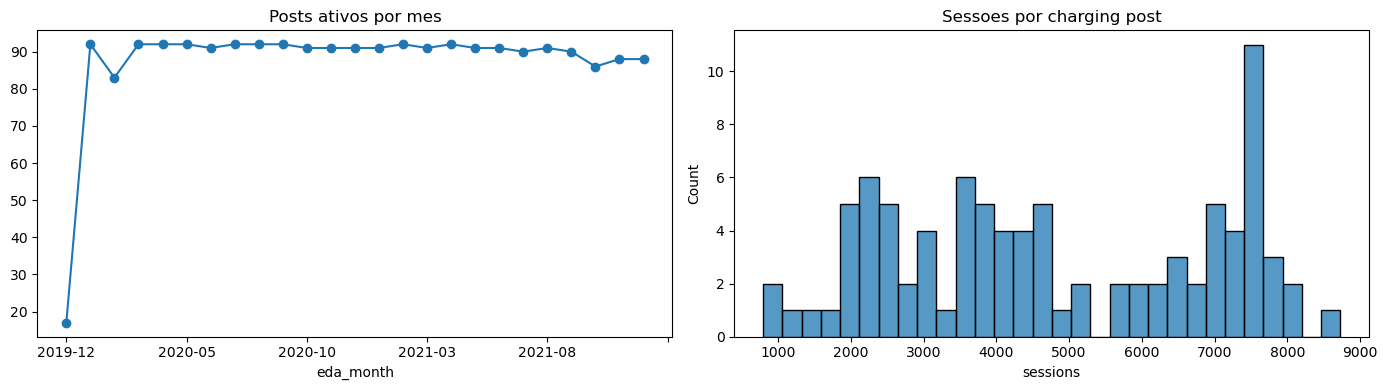

In [91]:
posts_by_month = df.groupby("eda_month")["charging_post_id"].nunique().rename("active_posts")
sessions_per_post = df.groupby("charging_post_id").size().rename("sessions")
post_summary = df.groupby("charging_post_id")["is_abnormal"].agg(sessions="size", abnormal_rate="mean")
post_summary["abnormal_rate"] *= 100
display(posts_by_month.to_frame())
display(sessions_per_post.describe().to_frame())
display(post_summary.sort_values("sessions", ascending=False).head(20))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
posts_by_month.plot(ax=axes[0], marker="o", title="Posts ativos por mes")
sns.histplot(sessions_per_post, bins=30, ax=axes[1])
axes[1].set_title("Sessoes por charging post")
plt.tight_layout()
save_fig("posts_activity")
plt.show()

A evolução dos charging posts ativos e a distribuição das sessões descrevem a utilização da infraestrutura. Uma abnormal rate elevada num post com poucas observações é incerta e não demonstra um efeito causal.

**O que significa para o negócio.** Mostra como a rede evolui (postos novos, postos parados) e se a carga está bem distribuída. Os postos com muitas sessões e uma taxa de falhas claramente acima da média são os candidatos óbvios a manutenção. Nos postos com poucas sessões, convém ter cuidado antes de tirar conclusões.

### Concentração e estabilidade por posto
A curva de Pareto mostra que fração dos utilizadores e dos postos concentra as sessões. O scatter compara volume e abnormal rate por posto: a dispersão é maior nos postos pequenos, onde a taxa é menos fiável.

**O que é a curva de Pareto (em termos simples).** Imagine ordenar todos os postos (ou clientes) do mais usado para o menos usado. A curva mostra quanto do total de sessões é feito pelos primeiros 10%, 20%, 30%... A linha tracejada diagonal seria o caso em que todos os postos têm o mesmo movimento. Quanto mais a curva «sobe depressa» acima da diagonal, mais o movimento está concentrado em poucos. O nome vem da regra de Pareto ou regra 80/20: muitas vezes, cerca de 20% dos clientes geram cerca de 80% das vendas.

**O que significa para o negócio.** Se poucos postos fazem a maior parte das sessões, uma avaria nesses postos afeta muitos clientes, por isso merecem manutenção prioritária e, se possível, um posto de reserva. Se poucos clientes fazem a maior parte das sessões, o comportamento desses clientes pesa muito nos números globais.

**Gráfico de pontos (à direita).** Cada ponto é um posto: quanto mais à direita, mais sessões; quanto mais acima, mais falhas. Os postos com poucas sessões ficam muito dispersos (um posto com 2 sessões e 1 falha tem 50% de falhas, mas isso não quer dizer nada). Quanto mais sessões, mais os pontos se aproximam da média. Os postos que continuam bem acima da média apesar de terem muitas sessões são os problemas reais.

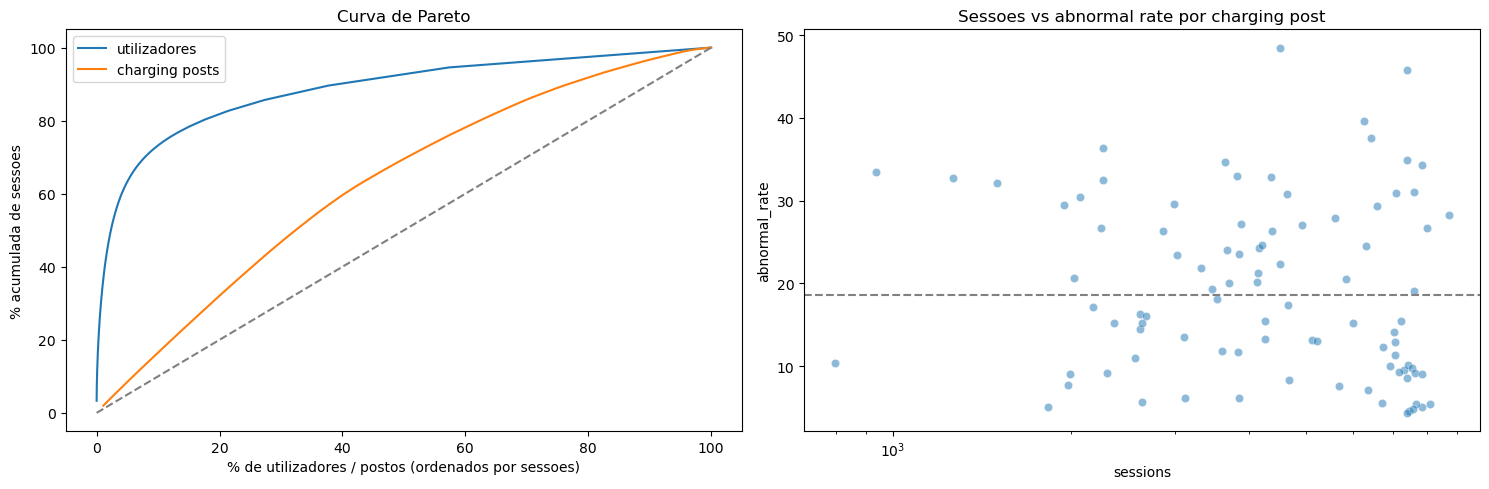

In [92]:
def pareto_curve(counts):
    values = counts.sort_values(ascending=False).to_numpy()
    return np.arange(1, len(values) + 1) / len(values) * 100, values.cumsum() / values.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for label, counts in [("utilizadores", sessions_per_user), ("charging posts", sessions_per_post)]:
    x, y = pareto_curve(counts)
    axes[0].plot(x, y, label=label)
axes[0].plot([0, 100], [0, 100], ls="--", color="grey")
axes[0].set_xlabel("% de utilizadores / postos (ordenados por sessoes)")
axes[0].set_ylabel("% acumulada de sessoes")
axes[0].set_title("Curva de Pareto")
axes[0].legend()

sns.scatterplot(data=post_summary, x="sessions", y="abnormal_rate", alpha=0.5, ax=axes[1])
axes[1].axhline(df["is_abnormal"].mean() * 100, color="grey", ls="--")
axes[1].set_xscale("log")
axes[1].set_title("Sessoes vs abnormal rate por charging post")
plt.tight_layout()
save_fig("pareto_posts_scatter")
plt.show()

## C.7. Temporal drift
Comparamos mensalmente o volume, a abnormal rate, as variáveis numéricas, os utilizadores, os charging posts e as categorias principais. O objetivo é decidir se o comportamento parece estável, se existem alterações temporais ou se a evidência é insuficiente.

**O que é o drift (em termos simples).** Drift é quando o mundo muda: passa a haver mais clientes, os hábitos mudam, a rede cresce, as falhas ficam mais ou menos frequentes. É como um mapa que fica desatualizado.

**O que significa para o negócio.** Um modelo que aprendeu com o passado pode ficar menos fiável se as coisas mudarem. Por isso é preciso testá-lo sempre em períodos posteriores aos que usou para aprender, acompanhar o seu desempenho depois de entrar em uso e voltar a treiná-lo de tempos a tempos.

In [93]:
drift_numeric = [c for c in ["temperature", "relative_humidity", "precipitation_mm", "electricity_price", "user_active_sessions_at_start"] if c in df.columns]
monthly_numeric = df.groupby("eda_month")[drift_numeric].median()
drift_table = monthly_rate[["sessions", "abnormal_rate"]].copy()
drift_table["distinct_users"] = users_by_month
drift_table["active_posts"] = posts_by_month
display(monthly_numeric)
display(drift_table)

,temperature,relative_humidity,precipitation_mm,electricity_price,user_active_sessions_at_start
eda_month,,,,,
2019-12,3.9,61.0,0.1,0.3784,0.0
2020-01,6.1,87.0,0.3,0.9014,0.0
2020-02,10.1,76.0,0.0,0.9014,0.0
2020-03,12.6,76.0,0.1,0.9014,0.0
2020-04,16.0,66.0,0.0,0.9014,0.0
2020-05,23.2,79.0,0.0,0.9014,0.0
2020-06,26.1,90.0,2.1,0.9014,0.0
2020-07,26.6,89.0,0.9,0.9014,0.0
2020-08,31.2,72.0,0.0,0.9014,0.0


,sessions,abnormal_rate,distinct_users,active_posts
eda_month,,,,
2019-12,17,29.411765,16,17
2020-01,6217,25.012064,1963,92
2020-02,1391,26.312006,516,83
2020-03,6392,24.780976,1797,92
2020-04,11136,22.054598,2622,92
2020-05,15033,19.184461,3153,92
2020-06,17513,15.993833,3185,91
2020-07,22032,18.223493,3704,92
2020-08,25562,20.061028,4733,92


### Gráficos do temporal drift
Medianas mensais normalizadas (z-score) para comparar variáveis com escalas diferentes e composição mensal do período tarifário.

**O que é o z-score (em termos simples).** Serve para comparar, na mesma figura, coisas medidas em unidades diferentes (graus, percentagens, euros). Para cada variável, diz quanto um mês está acima ou abaixo do que é habitual nessa variável: 0 é um mês normal, +1 é um mês acima do habitual (cerca de uma variação típica) e -1 é um mês abaixo. É como comparar notas de testes diferentes dizendo se cada uma ficou acima ou abaixo da média da turma, em vez de olhar para a nota em bruto. Atenção: cada variável é comparada apenas com o seu próprio histórico.

**O que significa para o negócio.** Se várias linhas se afastam do zero ao mesmo tempo, algo mudou nesse mês (por exemplo, a estação do ano ou uma mudança de preços). O gráfico de barras mostra como se reparte o movimento pelos períodos tarifários em cada mês; se a repartição muda, os clientes estão a carregar noutras alturas, o que afeta a receita e a carga da rede.

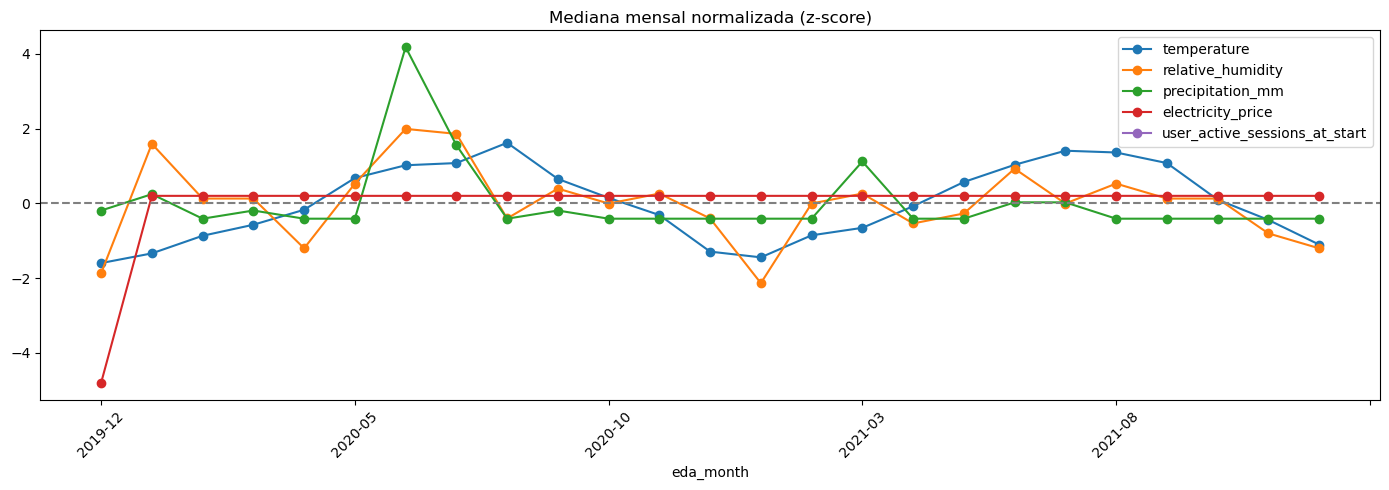

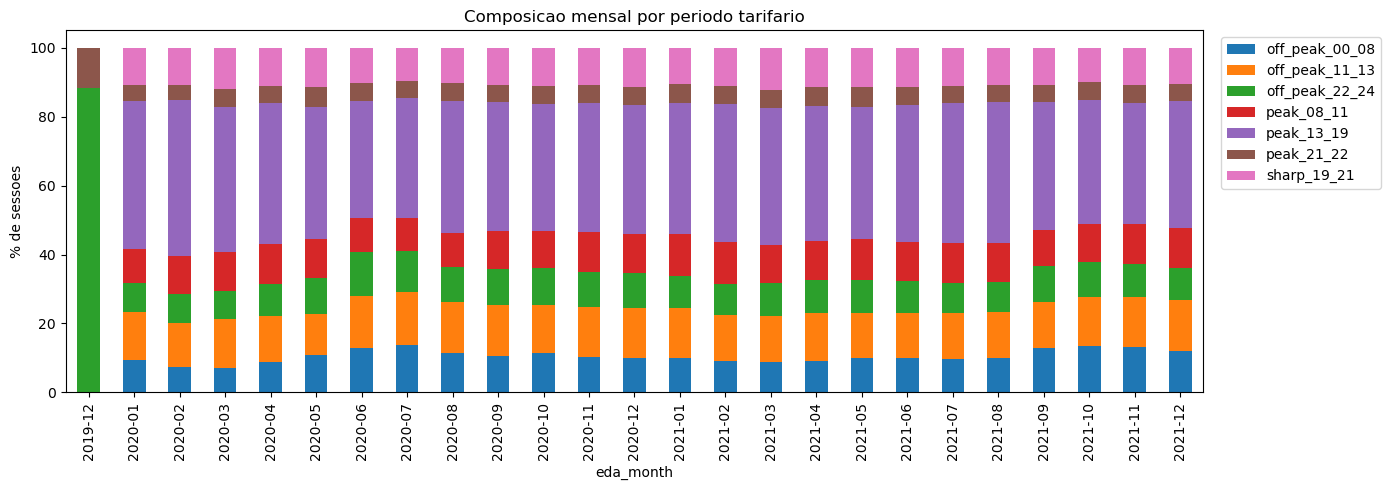

In [94]:
zscores = (monthly_numeric - monthly_numeric.mean()) / monthly_numeric.std()
ax = zscores.plot(figsize=(14, 5), marker="o")
ax.axhline(0, color="grey", ls="--")
ax.set_title("Mediana mensal normalizada (z-score)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
save_fig("drift_zscore")
plt.show()

tariff_share = pd.crosstab(df["eda_month"], df["tariff_period"], normalize="index") * 100
ax = tariff_share.plot(kind="bar", stacked=True, figsize=(14, 5))
ax.set_ylabel("% de sessoes")
ax.set_title("Composicao mensal por periodo tarifario")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
save_fig("drift_tariff_share")
plt.show()

# Parte D. Leakage e preparação para modelação

## D.1. Momento da previsão
O instante de previsão deve ser definido como imediatamente antes ou no momento de início da sessão, usando apenas informação conhecida até ao Start Time.

A variável end_cause só é conhecida depois do término da sessão. Portanto, todas as variáveis derivadas do resultado da sessão devem ser excluídas.

## D.2. Variáveis disponíveis no início

### Contexto
Estas variáveis podem ser utilizadas, desde que estejam disponíveis no momento de início:

- Charging Post ID
- Location Information
- District Name
- Temperature(℃)
- Relative Humidity(%)
- Precipitation(mm)
- electricity_price
- tariff_period
- hora, dia da semana, mês e feriado derivados de Start Time
- Order creation time não é utilizado: na Task 2 verificou-se que é posterior ao início da sessão na maioria dos casos, pelo que não está garantidamente disponível no momento da previsão.

### Sessão
Variáveis potencialmente disponíveis no início:

- UserID
- Charging Post ID
- Start Time
- Transaction power/kwh, apenas se for uma potência contratada/programada antes do início
- atributos de localização e tarifa

A interpretação de Transaction power/kwh deve ser confirmada. Se representar a energia efetivamente consumida durante a sessão, é leakage. Se representar um valor solicitado ou planeado antes do início, pode ser mantida.

### Histórico do charging post
As seguintes variáveis parecem explicitamente calculadas antes do início da sessão e devem ser mantidas:

- post_previous_sessions_1D
- post_previous_abnormal_1D
- post_previous_abnormal_rate_1D
- post_previous_sessions_7D
- post_previous_abnormal_7D
- post_previous_abnormal_rate_7D
- post_previous_sessions_30D
- post_previous_abnormal_30D
- post_previous_abnormal_rate_30D
- post_hours_since_previous_completed_session
- post_no_previous_completed_session
- post_hours_since_previous_completed_abnormal
- post_no_previous_completed_abnormal

Estas features são úteis para representar:

- carga recente do posto;
- taxa histórica de anomalias;
- existência de falhas recentes;
- tempo desde a última sessão ou falha.

### Histórico do utilizador
As seguintes variáveis também devem ser mantidas:

- is_new_user
- user_previous_sessions_30D
- user_previous_abnormal_30D
- user_previous_abnormal_rate_30D
- user_previous_sessions_180D
- user_previous_abnormal_180D
- user_previous_abnormal_rate_180D
- user_previous_sessions_730D
- user_previous_abnormal_730D
- user_previous_abnormal_rate_730D
- user_days_since_previous_completed_session
- user_no_previous_completed_session
- user_days_since_previous_completed_abnormal
- user_no_previous_completed_abnormal
- user_active_sessions_at_start (é especialmente importante para representar concorrência ou utilização simultânea do utilizador. Deve ser mantida se for realmente um snapshot calculado no instante de início)

## D.3. Variáveis com data leakage
Exclui-se qualquer variável que seja derivada do resultado da sessão, como:
| Variável                    | Motivo                                      |
|-----------------------------|---------------------------------------------|
| `end_cause`                 | É o próprio alvo                            |
| `End Time`                  | Só é conhecido depois da sessão terminar    |
| `Payment time`              | O pagamento ocorre depois ou perto do final |
| `Electricity cost/Yuan`     | Depende da energia consumida                |
| `Service charge/Yuan`       | É calculado para a sessão                   |
| `Transaction Amount/Yuan`   | Resultado financeiro da sessão              |
| `Actual Payment/Yuan`       | Só é conhecido depois do pagamento          |

Excluem-se também variáveis consoante a semântica, como:
| Variável                 | Motivo                                                                 |
|--------------------------|------------------------------------------------------------------------|
| `Transaction power/kwh`  | Excluída: representa a energia transacionada na sessão, só conhecida no fim |
| `Temperature(℃)`         | Mantida: o enunciado indica que se trata de estimativa/previsão disponível no início |
| `Relative Humidity(%)`   | Mantida: mesma justificação da temperatura                            |
| `Precipitation(mm)`      | Mantida: mesma justificação da temperatura                            |

## D.4. Conjunto final de variáveis recomendadas para modelação

### Features temporais
Derivadas de Start Time, estas variáveis representam o instante de início da sessão e podem ser utilizadas como features:
- start_hour
- start_day_of_week
- start_day_of_month
- start_month
- is_holiday (se existir informação sobre feriados, pode ser derivada de Start Time)
- is_weekend (derivada de start_day_of_week, indica se é fim de semana)

Para tariff_period, não é necessário criar novamente a hora se o período tarifário estiver correto, mas manter start_hour permite capturar padrões adicionais.

### Features de contexto
Estas variáveis representam o contexto da sessão e podem ser utilizadas como features:
- charging_post_id
- location_information
- district_name
- electricity_price
- tariff_period
- temperature
- relative_humidity
- precipitation

### Features de histórico do charging post
Estas variáveis representam o histórico do charging post e podem ser utilizadas como features:
- post_previous_sessions_1D
- post_previous_abnormal_1D
- post_previous_abnormal_rate_1D
- post_previous_sessions_7D
- post_previous_abnormal_7D
- post_previous_abnormal_rate_7D
- post_previous_sessions_30D
- post_previous_abnormal_30D
- post_previous_abnormal_rate_30D
- post_hours_since_previous_completed_session
- post_no_previous_completed_session
- post_hours_since_previous_completed_abnormal
- post_no_previous_completed_abnormal

### Features de histórico do utilizador
Estas variáveis representam o histórico do utilizador e podem ser utilizadas como features:
- is_new_user é parcialmente redundante com as contagens de sessões anteriores, mas pode ser mantida para representar explicitamente a ausência de histórico
- user_previous_sessions_30D
- user_previous_abnormal_30D
- user_previous_abnormal_rate_30D
- user_previous_sessions_180D
- user_previous_abnormal_180D
- user_previous_abnormal_rate_180D
- user_previous_sessions_730D
- user_previous_abnormal_730D
- user_previous_abnormal_rate_730D
- user_days_since_previous_completed_session
- user_no_previous_completed_session
- user_days_since_previous_completed_abnormal
- user_no_previous_completed_abnormal
- user_active_sessions_at_start

## D.5. IDs e risco de memória

Utilizar `userid` e `charging_post_id` como features pode introduzir **risco de memória** no modelo, uma vez que estes identificadores podem ser únicos ou quase únicos para cada sessão. Isto significa que o modelo pode aprender padrões específicos para cada ID, em vez de generalizar para novos utilizadores ou postos de carregamento.

Opções para lidar com UserId:

- Modelo principal: não utilizar o UserID bruto; usar apenas histórico do utilizador.
- Modelo de comparação: usar encoding de frequência calculado apenas no treino.
- Target encoding: apenas dentro de cada fold temporal, nunca calculado no dataset completo.
- Recomendação: excluir o UserID bruto do primeiro modelo.

Recomendação para Charging Post ID:

- manter Charging Post ID como categórica para modelos de árvore;
- para modelos lineares, usar one-hot apenas se o número de postos for moderado;
- comparar com uma versão sem o ID;
- usar frequency encoding calculado exclusivamente no treino se houver muitos postos.

## D.6. Importância das features
A importância das features deve ser avaliada com base em métricas de desempenho do modelo.

Treinar pelo menos estes modelos com o mesmo split temporal:

| Modelo | Features |
|--------|----------|
| A | Contexto + sessão |
| B | A + histórico do charging post |
| C | A + histórico do utilizador |
| D | A + histórico do posto + histórico do utilizador |

Comparar:
- macro F1 score,
- balanced accuracy;
- F1 da classe anormal (`is_abnormal = 1`);
- recall da classe anormal;
- PR-AUC para a classificação binária;
- calibração das probabilidades.

A diferença de desempenho entre os modelos ajuda a perceber a importância relativa das features de contexto, histórico do posto e histórico do utilizador.
 - valor do histórico do posto = desempenho do modelo B - desempenho do modelo A
 - valor do histórico do utilizador = desempenho do modelo C - desempenho do modelo A
 - valor combinado = desempenho do modelo D - desempenho do modelo A

## D.7. Estratégia de pré-processamento

A estratégia de pré-processamento é fundamental para garantir a qualidade dos dados antes de aplicar qualquer técnica de análise ou modelagem. Ela envolve várias etapas que ajudam a preparar os dados para a análise, como limpeza, transformação e normalização.

Numéricas, categóricas e temporais são tratadas de forma diferente, com técnicas específicas para cada tipo de variável. A escolha das técnicas de pré-processamento deve ser baseada na natureza dos dados e nos objetivos da análise ou modelagem.

#### Numéricas
Não substituir automaticamente valores em falta por zero, porque missing e zero têm significados diferentes.

Para as variáveis históricas, os indicadores post_no_previous_* e user_no_previous_* são mantidos como informação explícita de ausência de histórico, e os `NaN` das quatro variáveis de tempo histórico são substituídos por `-1` dentro do pipeline (secção D.9).

#### Categóricas
- Location Information: one-hot encoding;
- District Name: one-hot encoding;
- tariff_period: one-hot encoding;
- Charging Post ID: one-hot ou frequency encoding, dependendo da cardinalidade;
- UserID: preferencialmente excluir do primeiro modelo ou aplicar encoding controlado.

Utilizar handle_unknown = "ignore", para categorias novas no validation/test.

#### Target encoding
Se for utilizado para postos ou utilizadores:
- calcular estatísticas apenas no treino;
- em teste, usar apenas o mapa aprendido no treino;
- nunca calcular target encoding antes do split.

### Tratamento dos valores em falta nas variáveis históricas

Os valores em falta nas variáveis de tempo histórico ocorrem quando **não existe histórico anterior disponível**. Por exemplo, quando `user_no_previous_completed_session = 1` não existe nenhuma sessão anterior concluída para esse utilizador, pelo que não é possível calcular `user_days_since_previous_completed_session`.

Como estes `NaN` têm significado, são substituídos por `-1` dentro do pipeline de pré-processamento, e não no `DataFrame` usado na EDA. Este valor é adequado porque um tempo decorrido não pode ser negativo:

- um valor positivo representa o tempo efetivamente decorrido desde a sessão anterior;
- `-1` representa a ausência de sessão anterior.

As variáveis indicadoras `no_previous` são mantidas, uma vez que identificam explicitamente a ausência de histórico.

## D.8. Class imbalance e métricas de avaliação
O dataset apresenta um **desbalanceamento de classes**, com a classe anormal (`is_abnormal = 1`) a representar cerca de 18,6% das sessões. Este desbalanceamento pode afetar o desempenho do modelo, tornando-o tendencioso para a classe majoritária.

Para lidar com este desbalanceamento, recomenda-se:
- começar com class_weights ou balanced loss functions;
- avaliar métricas como macro-F1 e balanced accuracy, não apenas accuracy;
- monitorizar recall das falhas;
- utilizar matriz de confusão normalizada;
- evitar oversampling aleatório antes do split temporal, para não introduzir leakage.

SMOTE não deve ser aplicado diretamente sem cuidado, porque pode misturar períodos temporais, pode criar sessões sintéticas sem significado físico e pode usar implicitamente informação de validação se aplicado antes do split.

Se o desempenho for insuficiente:
- agrupar causas extremamente raras numa classe other_fault ou utilizar um modelo hierárquico: normal/user stop vs fault -tipo de falha apenas para as sessões classificadas como fault.

## D.9. Split temporal e pipeline de pré-processamento
O split temporal é essencial para evitar **data leakage** e garantir que o modelo é avaliado em dados que representam o futuro em relação ao treino.

Deve ser realizado por Start Time: as sessões mais antigas servem para treinar e as mais recentes para testar, como acontece em produção. Não se faz split por utilizador ou charging post: o mesmo utilizador ou posto aparece no treino e no teste, e as features de histórico já resumem o passado de cada um.

Os dados são divididos em dois conjuntos:
- Treino: 70% das sessões mais antigas;
- Teste: 30% das sessões mais recentes.

A validação é feita dentro do treino, com validação temporal expansiva. Alternativamente, utilizar datas fixas depois de inspecionar o intervalo temporal.

O processo deve ser:
1. Ordenar o dataset por Start Time;
2. Dividir em treino e teste com base nas proporções ou datas definidas;
3. Ajustar imputação, normalização e codificação apenas com os dados de treino;
4. Avaliar decisões de modelação com validação temporal expansiva dentro do treino;
5. Usar o conjunto de teste apenas para avaliação final do modelo.

Para seleção de hiperparâmetros, usar validação temporal expansiva:
Fold 1: treino inicial -> validação seguinte
Fold 2: treino maior   -> validação seguinte
Fold 3: treino maior   -> validação seguinte

Como as features históricas incluem janelas até 730 dias, pode ser usado um gap temporal entre treino e teste se as features forem recalculadas a partir de dados brutos.

**Como ler o gráfico e a tabela abaixo.** No gráfico, as barras à esquerda da linha vermelha são o passado (usado para o modelo aprender) e as da direita são o futuro (usado para testar). Imita o que acontece na vida real: aprende-se com o que já aconteceu e pretende-se acertar no que vem a seguir. A tabela repete essa ideia dentro do passado, em quatro rondas: em cada uma o modelo aprende até uma data e é testado nos meses seguintes.

**O que significa para o negócio.** Dá uma estimativa honesta de como o modelo se comportará quando for usado a sério. Se a percentagem de falhas varia de ronda para ronda, o desempenho também vai variar de período para período, por isso o resultado deve ser apresentado ronda a ronda e não como um único número.

In [95]:
# Variáveis derivadas apenas de start_time (sem leakage); ordenação estável por start_time
model_df = df.sort_values("start_time", kind="stable").reset_index(drop=True)
model_df["start_hour"] = model_df["start_time"].dt.hour
model_df["start_day_of_week"] = model_df["start_time"].dt.dayofweek
model_df["start_month"] = model_df["start_time"].dt.month
model_df["is_weekend"] = (model_df["start_day_of_week"] >= 5).astype(int)

history_time_columns = [
    "post_hours_since_previous_completed_session",
    "post_hours_since_previous_completed_abnormal",
    "user_days_since_previous_completed_session",
    "user_days_since_previous_completed_abnormal",
]
history_other_columns = [
    c for c in model_df.columns
    if (c.startswith("post_") or c.startswith("user_")) and c not in history_time_columns
] + ["is_new_user"]
time_features = ["start_hour", "start_day_of_week", "start_month", "is_weekend"]
context_numeric = ["electricity_price", "temperature", "relative_humidity", "precipitation_mm"]
context_categorical = ["location_information", "district_name", "tariff_period"]

# UserID e Charging Post ID ficam fora do primeiro modelo (risco de memória, secção D.5)
numeric_features = time_features + context_numeric + history_other_columns
feature_columns = numeric_features + history_time_columns + context_categorical
print(f"{len(feature_columns)} features:", len(numeric_features), "numéricas,", len(history_time_columns),
      "de tempo histórico,", len(context_categorical), "categóricas")

39 features: 32 numéricas, 4 de tempo histórico, 3 categóricas


,sessões,início,fim,abnormal rate
treino,308753,2019-12-31 21:27:03,2021-07-30 14:43:40,0.182949
teste,132324,2021-07-30 14:43:55,2021-12-31 23:52:14,0.192316


Sessões de treino que terminam depois do corte (2021-07-30 14:43:55): 47


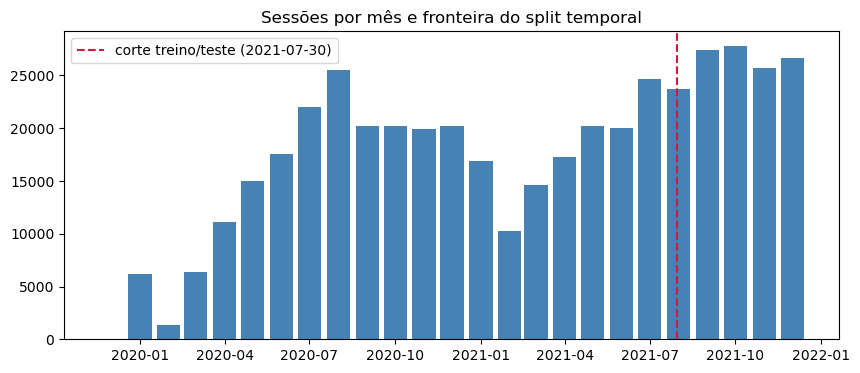

In [96]:
# Corte temporal 70/30 por start_time
cut_time = model_df["start_time"].iloc[int(len(model_df) * 0.70)]
train_df = model_df[model_df["start_time"] < cut_time]
test_df = model_df[model_df["start_time"] >= cut_time]

summary = pd.DataFrame({
    "sessões": [len(train_df), len(test_df)],
    "início": [train_df["start_time"].min(), test_df["start_time"].min()],
    "fim": [train_df["start_time"].max(), test_df["start_time"].max()],
    "abnormal rate": [train_df["is_abnormal"].mean(), test_df["is_abnormal"].mean()],
}, index=["treino", "teste"])
display(summary)

overlap = (train_df["end_time"] >= cut_time).sum()
print(f"Sessões de treino que terminam depois do corte ({cut_time}): {overlap}")

monthly = model_df.groupby(model_df["start_time"].dt.to_period("M")).size()
plt.figure(figsize=(10, 4))
plt.bar(monthly.index.to_timestamp(), monthly.values, width=25, color="steelblue")
plt.axvline(cut_time, color="crimson", linestyle="--", label=f"corte treino/teste ({cut_time.date()})")
plt.title("Sessões por mês e fronteira do split temporal")
plt.legend()
save_fig("temporal_split")
plt.show()

In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Sem escalonamento: adequado a modelos de árvore; adicionar StandardScaler para modelos lineares
preprocessor = ColumnTransformer([
    ("history_time", SimpleImputer(strategy="constant", fill_value=-1), history_time_columns),
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), context_categorical),
])

X_train, y_train = train_df[feature_columns], train_df["is_abnormal"]
X_test, y_test = test_df[feature_columns], test_df["is_abnormal"]

X_train_t = preprocessor.fit_transform(X_train)  # ajustado apenas no treino
X_test_t = preprocessor.transform(X_test)
print("Treino:", X_train_t.shape, "| Teste:", X_test_t.shape)
print("NaN após pré-processamento:", int(np.isnan(X_train_t.data).sum()), "(treino),",
      int(np.isnan(X_test_t.data).sum()), "(teste)")
print("Categorias não vistas no treino mas presentes no teste:")
for col, cats in zip(context_categorical, preprocessor.named_transformers_["categorical"].categories_):
    print(f"  {col}: {(~test_df[col].isin(cats)).sum()} sessões")

Treino: (308753, 59) | Teste: (132324, 59)
NaN após pré-processamento: 0 (treino), 0 (teste)
Categorias não vistas no treino mas presentes no teste:
  location_information: 0 sessões
  district_name: 0 sessões
  tariff_period: 0 sessões


In [98]:
# Esquema de validação expansiva dentro do treino (protocolo completo na Task 2)
from sklearn.model_selection import TimeSeriesSplit

folds = []
for k, (tr, va) in enumerate(TimeSeriesSplit(n_splits=4).split(train_df), start=1):
    folds.append({
        "fold": k,
        "treino": len(tr),
        "validação": len(va),
        "início validação": train_df["start_time"].iloc[va[0]].date(),
        "fim validação": train_df["start_time"].iloc[va[-1]].date(),
        "abnormal rate validação": train_df["is_abnormal"].iloc[va].mean(),
    })
display(pd.DataFrame(folds).set_index("fold"))

,treino,validação,início validação,fim validação,abnormal rate validação
fold,,,,,
1,61753,61750,2020-07-07,2020-09-27,0.195077
2,123503,61750,2020-09-27,2020-12-31,0.167449
3,185253,61750,2020-12-31,2021-05-03,0.158980
4,247003,61750,2021-05-03,2021-07-30,0.195449


# Parte E. Síntese final

## E.1. Problemas descobertos

- Os `NaN` das quatro variáveis de tempo histórico correspondem a ausência de histórico anterior, não a erros de qualidade.
- Existem ordens temporais atípicas (1.554 pagamentos antes do início da sessão e 248.588 sessões com início anterior a `order_creation_time`), mantidas por o enunciado não impor essa ordem.
- A classe anormal (`end_cause` fora de "Charging ends normally" e "User stops charging") representa cerca de 18,6% das sessões.
- O volume mensal e a abnormal rate variam ao longo do tempo (Parte C), pelo que a avaliação tem de respeitar a ordem temporal.

## E.2. Evidência das decisões

- Não há linhas duplicadas nem valores fora dos intervalos plausíveis (A.4 a A.8); apenas as linhas totalmente vazias são removidas.
- Os outliers e as ordens temporais atípicas foram identificados e mantidos (A.10, B.3).
- O split por `start_time` e o pré-processamento ajustado apenas no treino evitam leakage (D.9).

## E.3. Variáveis retidas

- Contexto: localização, distrito, período tarifário, preço, temperatura, humidade e precipitação.
- Temporais derivadas de `start_time`: hora, dia da semana, mês e fim de semana.
- Histórico do posto e do utilizador (incluindo os indicadores `no_previous`).
- Excluídas: variáveis posteriores ao início da sessão (D.3), `order_creation_time`, e `UserID` e `Charging Post ID` no primeiro modelo (D.5).

## E.4. Limitações

- Que a meteorologia e o preço estão disponíveis no início da sessão é assumido pelo enunciado e não é verificável nos dados.
- As variáveis de histórico vêm pré-calculadas, pelo que não é possível recalculá-las dentro de cada fold.
- Nos primeiros meses o volume é baixo e o histórico é curto, o que afeta os primeiros folds.
- O alvo agrega causas de falha heterogéneas.

## E.5. Implicações para a avaliação

- Validação expansiva dentro do treino, com o teste final intocado até ao protocolo fechado.
- Pré-processamento ajustado dentro de cada fold e métricas reportadas por fold, incluindo a estabilidade entre períodos.
- Definição do protocolo, das métricas e da baseline na Task 2.